# 08.04 — Brick 4: Narrative Communities

This notebook is **only Brick 4**.

It does not explain NLP embeddings.  
It does not rebuild the network.  
It does not discuss success outcomes.  
It does not focus on centrality/betweenness roles.

Its job is to answer one reader question:

> What narrative communities emerged from the plot-similarity network, and how can they be shown clearly?

## Thesis-level idea

The communities are not strict genres.

They are **narrative neighborhoods** discovered from plot similarity.

So this brick builds figures that explain communities as:

```text
detected graph communities
→ major interpretable communities
→ human-readable narrative labels
→ representative examples
→ community profiles
```

## Figures produced

```text
outputs/thesis_bricks/04_narrative_communities/figures/
```

1. `01_community_detection_concept.png`  
2. `02_major_communities_lollipop.png`  
3. `03_major_minor_community_split.png`  
4. `04_top_communities_index_table.png`  
5. `05_community_profile_sheet_CXX.png` for top communities  
6. `06_representative_films_gallery.png`  
7. `07_community_size_vs_median_year.png`  
8. `08_community_genre_mix_small_multiples.png`  
9. `09_community_interpretation_summary.png`  

## Design rule

No giant 23-row wall of text in the main thesis.

Use:
- one compact index table,
- selected one-page community sheets,
- appendix tables for the full list.


## 0. Setup

In [ ]:

import os, re, math, textwrap, warnings
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.patheffects as pe

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 220)
pd.set_option("display.max_colwidth", 240)

COL = {
    "ink": "#222222",
    "muted": "#62666D",
    "grid": "#E4E7EB",
    "panel": "#F7F8FA",
    "blue": "#2F6FB3",
    "orange": "#D06C45",
    "green": "#2F8F5B",
    "purple": "#7A5BC2",
    "red": "#C94C4C",
    "yellow": "#D9A21B",
    "light_blue": "#E8F1FB",
    "light_orange": "#FBEADF",
    "light_green": "#E6F4EC",
    "light_purple": "#EFEAFB",
    "light_gray": "#F2F4F7",
    "white": "#FFFFFF",
}

COMM_COLORS = [
    "#4E79A7", "#F28E2B", "#59A14F", "#E15759", "#76B7B2", "#9C755F",
    "#EDC948", "#B07AA1", "#FF9DA7", "#BAB0AC", "#2F6FB3", "#D06C45",
    "#2F8F5B", "#7A5BC2", "#C94C4C", "#D9A21B", "#5C6BC0", "#26A69A",
    "#AB47BC", "#8D6E63", "#78909C", "#EC407A", "#43A047", "#FB8C00",
    "#6D4C41", "#00ACC1"
]

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": COL["ink"],
    "axes.labelcolor": COL["ink"],
    "xtick.color": COL["ink"],
    "ytick.color": COL["ink"],
    "text.color": COL["ink"],
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "savefig.dpi": 320,
    "figure.dpi": 130,
})

def save_fig(fig, name, dpi=320):
    png = FIG_DIR / name
    svg = FIG_DIR / name.replace(".png", ".svg")
    fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white")
    fig.savefig(svg, bbox_inches="tight", facecolor="white")
    print("Saved:", png)
    print("Saved:", svg)

def save_table(df, name):
    path = TABLE_DIR / name
    df.to_csv(path, index=False, encoding="utf-8")
    print("Saved:", path)
    return path

def write_text(txt, name):
    path = TEXT_DIR / name
    path.write_text(txt, encoding="utf-8")
    print("Saved:", path)
    return path

def wrap_text(s, width=42):
    if pd.isna(s):
        return ""
    return "\n".join(textwrap.wrap(str(s), width=width))

def shorten(s, width=90):
    if pd.isna(s):
        return ""
    return textwrap.shorten(str(s).replace("\n", " "), width=width, placeholder="...")

def clean_title(x):
    if pd.isna(x):
        return ""
    return str(x).replace("\n", " ").strip()

def title_block(fig, title, subtitle=None, x=0.05, y=0.965):
    fig.text(x, y, title, ha="left", va="top", fontsize=22, fontweight="bold", color=COL["ink"])
    if subtitle:
        fig.text(x, y - 0.055, subtitle, ha="left", va="top", fontsize=12.5, color=COL["muted"])

def community_color(cid):
    try:
        return COMM_COLORS[int(cid) % len(COMM_COLORS)]
    except Exception:
        return COL["blue"]

def safe_read(path):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    print("Missing:", path)
    return None

def fmt_int(x):
    try:
        return f"{int(round(float(x))):,}"
    except Exception:
        return "—"

def parse_examples(s, max_n=4):
    if pd.isna(s):
        return []
    text = str(s)
    # Many of your CSV example columns are comma/semicolon-separated title lists.
    parts = re.split(r";|,|\|", text)
    out = []
    for p in parts:
        p = p.strip()
        if p and p.lower() not in ["nan", "none"]:
            out.append(p)
        if len(out) >= max_n:
            break
    return out

def first_available(row, cols):
    for c in cols:
        if c in row.index and pd.notna(row[c]) and str(row[c]).strip():
            return str(row[c])
    return ""

def parse_genre_mix(x, max_n=5):
    if pd.isna(x):
        return []
    s = str(x)
    chunks = re.split(r",|;", s)
    pairs = []
    for ch in chunks:
        ch = ch.strip()
        if not ch:
            continue
        # Try forms: "Drama: 35.2%" or "Drama (35.2%)"
        genre = re.sub(r"[:(].*", "", ch).strip()
        m = re.search(r"([0-9]+\.?[0-9]*)", ch)
        value = float(m.group(1)) if m else np.nan
        if genre:
            pairs.append((genre, value))
        if len(pairs) >= max_n:
            break
    return pairs

def detect_edge_cols(df):
    pairs = [("source", "target"), ("source_id", "target_id"), ("src", "dst"), ("u", "v"), ("node1", "node2"), ("from", "to")]
    for a, b in pairs:
        if a in df.columns and b in df.columns:
            return a, b
    return df.columns[0], df.columns[1]


## 1. Project paths

In [ ]:

try:
    from google.colab import drive
    if Path("/content/drive/MyDrive").exists():
        print("Google Drive already mounted.")
    else:
        drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped or failed:", e)

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()

PROCESSED_CORE_DIR = PROJECT_DIR / "processed" / "core"
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
PROCESSED_FEATURES_DIR = PROJECT_DIR / "processed" / "features"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"

FINAL_DIR = PROJECT_DIR / "outputs" / "thesis_bricks" / "04_narrative_communities"
FIG_DIR = FINAL_DIR / "figures"
TABLE_DIR = FINAL_DIR / "tables"
TEXT_DIR = FINAL_DIR / "text"

for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("FINAL_DIR:", FINAL_DIR)


Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
FINAL_DIR: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities


## 2. Load files

In [ ]:

FILES = {
    "nodes": PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "edges": PROCESSED_NETWORK_DIR / "semantic_network_edges_mutual_knn.csv",
    "community_labels": OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv",
    "community_size": OUTPUT_TABLES_DIR / "community_size_overview.csv",
    "major_community_table": OUTPUT_TABLES_DIR / "major_community_thesis_table.csv",
    "community_representatives": OUTPUT_TABLES_DIR / "community_representative_films_long.csv",
    "top_visible_central": OUTPUT_TABLES_DIR / "top_visible_central_films_per_community.csv",
    "community_success": OUTPUT_TABLES_DIR / "final_story_tables" / "final_community_success_summary.csv",
}

for k, p in FILES.items():
    print(f"{k:26s}", p.exists(), "-", p)

nodes = safe_read(FILES["nodes"])
edges = safe_read(FILES["edges"])
community_labels = safe_read(FILES["community_labels"])
community_size = safe_read(FILES["community_size"])
major_community_table = safe_read(FILES["major_community_table"])
community_representatives = safe_read(FILES["community_representatives"])
top_visible_central = safe_read(FILES["top_visible_central"])
community_success = safe_read(FILES["community_success"])

if nodes is None or community_labels is None:
    raise FileNotFoundError("This brick needs semantic_network_nodes_lcc.csv and community_manual_labeling_template_labeled.csv.")

label_col = "suggested_label_manual" if "suggested_label_manual" in community_labels.columns else "narrative_label"
note_col = "interpretation_note_manual" if "interpretation_note_manual" in community_labels.columns else "interpretation"

# Build unified community table
comm = community_labels.copy()
if "n_films" not in comm.columns:
    comm = comm.merge(nodes.groupby("community_id").size().reset_index(name="n_films"), on="community_id", how="left")

comm["community_id"] = comm["community_id"].astype(int)
comm = comm.sort_values("n_films", ascending=False).reset_index(drop=True)

total_communities = nodes["community_id"].nunique()
total_nodes = len(nodes)
major_threshold = 100
major_count = (comm["n_films"] >= major_threshold).sum()
minor_count = total_communities - major_count

# Add size share if missing
if "share_of_network_pct" not in comm.columns:
    comm["share_of_network_pct"] = comm["n_films"] / total_nodes * 100

print()
print("nodes:", nodes.shape)
print("communities in nodes:", total_communities)
print("major communities >=100 films:", major_count)
print("minor communities:", minor_count)
print("manual label rows:", comm.shape)
display(comm.head())


nodes                      True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_nodes_lcc.csv
edges                      True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_edges_mutual_knn.csv
community_labels           True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_manual_labeling_template_labeled.csv
community_size             True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_size_overview.csv
major_community_table      True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/major_community_thesis_table.csv
community_representatives  True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_representative_films_long.csv
top_visible_central        True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_visible_central_films_per_community.csv
community_success          True - /content/drive/MyDrive/thesis_movie_project/outp

,interpretation_priority,community_id,n_films,share_of_network_pct,top_primary_genres,year_range,median_year,median_vote_count,median_vote_average,revenue_available_pct,central_titles_weighted_degree,bridging_titles_betweenness,visible_titles_vote_count,suggested_label_manual,interpretation_note_manual
0,1,14,1792,9.33,Drama (588); Comedy (389); Horror (209); Thriller (126); Action (116); Romance (104),1990-2024,2014.0,82.0,6.1,36.38,The House (2024); The Kindred (2021); Pistas para volver a casa (2015); Beyond the Law (2019); The Boogeyman (2023); The Bachelors (2017); The Harbinger (2022); House at the End of the Street (2012),Jungle (2017); The Covenant (2006); Imagining Argentina (2003); Rio (2011); Celebrity (1998); I Don't Kiss (1991),Forrest Gump (1994); The Hunger Games (2012); Spirited Away (2001); Man of Steel (2013); Her (2013); Avatar: The Way of Water (2022); Life Is Beautiful (1997); The Notebook (2004),"Broad personal drama, family disruption, and domestic threat","This large community appears to collect broad character- and family-centered plots, often with domestic threat, grief, or life-transition elements. Because its visible examples span prestige drama, fantasy adventure, and intimate thrill..."
1,2,22,1735,9.04,Drama (632); Comedy (580); Romance (93); Horror (73); Thriller (72); Action (71),1990-2024,2014.0,79.0,6.3,32.16,"Amer (2009); Something New (2016); Mayday (2021); Sexo, Amor e Traição (2004); María (and Everybody Else) (2016); Dating Santa (2023); Ex 2: Still Friends (2011); Mascarpone (2021)",The Bandit (1996); Darkland (2017); Descent Into Darkness (2013); (Im)perfetti Criminali (2022); Quasimodo d'el Paris (1999); The Sicilian Girl (2008),Coco (2017); The Incredibles (2004); La La Land (2016); Call Me by Your Name (2017); Fifty Shades of Grey (2015); Pan's Labyrinth (2006); (500) Days of Summer (2009); Birds of Prey (and the Fantabulous Emancipation of One Harley Quinn) ...,"Relationship drama, romantic comedy, and emotional-family crossover","This community seems to group relationship-centered and emotionally expressive narratives, especially romance, family bonds, and comedy-drama plots. The presence of mainstream animation and fantasy titles suggests an affective/emotional..."
2,3,12,1517,7.90,Drama (446); Comedy (275); Action (244); Animation (153); Romance (84); Horror (63),1990-2024,2013.0,61.0,6.6,34.15,"Demon Slayer: Kimetsu no Yaiba - Sibling's Bond (2019); Samurai Cop (1991); Agitator (2001); Kabei: Our Mother (2008); Ring 2 (1999); My Tomorrow, Your Yesterday (2016); Black Angel (1998); Deadly Outlaw: Rekka (2002)","Mommy, I'm Scared (2006); Under Construction (2003); Man Push Cart (2006); Apartment 1303 (2007); Amaran (2024); Yoko (2012)",Finding Nemo (2003); Your Name. (2016); Alita: Battle Angel (2019); Pretty Woman (1990); Princess Mononoke (1997); The Last Samurai (2003); Manchester by the Sea (2016); Borat: Cultural Learnings of America for Make Benefit Glorious Nat...,Japanese/Korean action-animation and cross-cultural personal drama,"This neighborhood is strongly shaped by Japanese and Korean titles, anime-linked stories, and action-drama plots with personal or familial stakes. It should be read as a transnational semantic cluster combining East-Asian action, animat..."
3,4,2,1411,7.35,Drama (449); Comedy (414); Horror (157); Romance (80); Thriller (80); Action (65),1990-2024,2012.0,102.0,6.0,41.11,Amanda (2018); Verbo (2011); Rara (2016); The Stranger Within (2013); The Angel Maker (2023); You're Not Alone (2020); Headwinds (2011); In Their Sleep (2010),Die In One Day (2017); Animal Kingdom (2010); Agent Cody Banks (2003); Hope Springs (2003); Rose (2012); The Attic Expeditions (2001),Titanic (1997); Inside Out (2015); Toy Story (1995); Get Out (2017); Once Upon a Time... in Hollywood (2019); The Curious Case of Benjamin Button (2008); Green Book (2018); A Star Is Born (2018),"Coming-of-age, identity, and character-centered social drama","This community appears to emphasize 

## 3. Build community-level profile table

In [ ]:

# Merge optional success/profile info if available.
profile = comm.copy()

if community_success is not None:
    cols_to_add = [c for c in community_success.columns if c not in profile.columns or c == "community_id"]
    profile = profile.merge(community_success[cols_to_add], on="community_id", how="left", suffixes=("", "_success"))

# Node-derived profile statistics
node_stats = (
    nodes
    .groupby("community_id")
    .agg(
        n_nodes=("community_id", "size"),
        median_year=("release_year", "median") if "release_year" in nodes.columns else ("community_id", "size"),
        min_year=("release_year", "min") if "release_year" in nodes.columns else ("community_id", "size"),
        max_year=("release_year", "max") if "release_year" in nodes.columns else ("community_id", "size"),
        median_vote_count=("vote_count", "median") if "vote_count" in nodes.columns else ("community_id", "size"),
        median_vote_average=("vote_average", "median") if "vote_average" in nodes.columns else ("community_id", "size"),
    )
    .reset_index()
)

profile = profile.merge(node_stats, on="community_id", how="left", suffixes=("", "_node"))

# Central examples by community from top_visible_central
example_lookup = {}
if top_visible_central is not None:
    temp = top_visible_central.copy()
    for cid, g in temp.groupby("community_id"):
        titles = []
        for _, r in g.head(4).iterrows():
            if "title" in r.index:
                title = clean_title(r["title"])
                year = ""
                if "release_year" in r.index and pd.notna(r["release_year"]):
                    year = f" ({int(r['release_year'])})"
                titles.append(title + year)
        example_lookup[int(cid)] = titles

def get_examples(row):
    cid = int(row["community_id"])
    if cid in example_lookup and example_lookup[cid]:
        return "; ".join(example_lookup[cid])
    ex = first_available(row, ["visible_titles_vote_count", "central_titles_weighted_degree", "recognizable_examples"])
    return "; ".join(parse_examples(ex, max_n=4))

profile["selected_examples"] = profile.apply(get_examples, axis=1)

save_table(profile, "00_community_profile_table.csv")
display(profile.head(10))


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/tables/00_community_profile_table.csv


,interpretation_priority,community_id,n_films,share_of_network_pct,top_primary_genres,year_range,median_year,median_vote_count,median_vote_average,revenue_available_pct,central_titles_weighted_degree,bridging_titles_betweenness,visible_titles_vote_count,suggested_label_manual,interpretation_note_manual,narrative_label,median_revenue_percentile_year,median_popularity,median_weighted_degree,median_cast_size,median_top_cast_exposure_max,n_nodes,median_year_node,min_year,max_year,median_vote_count_node,median_vote_average_node,selected_examples
0,1,14,1792,9.33,Drama (588); Comedy (389); Horror (209); Thriller (126); Action (116); Romance (104),1990-2024,2014.0,82.0,6.10,36.38,The House (2024); The Kindred (2021); Pistas para volver a casa (2015); Beyond the Law (2019); The Boogeyman (2023); The Bachelors (2017); The Harbinger (2022); House at the End of the Street (2012),Jungle (2017); The Covenant (2006); Imagining Argentina (2003); Rio (2011); Celebrity (1998); I Don't Kiss (1991),Forrest Gump (1994); The Hunger Games (2012); Spirited Away (2001); Man of Steel (2013); Her (2013); Avatar: The Way of Water (2022); Life Is Beautiful (1997); The Notebook (2004),"Broad personal drama, family disruption, and domestic threat","This large community appears to collect broad character- and family-centered plots, often with domestic threat, grief, or life-transition elements. Because its visible examples span prestige drama, fantasy adventure, and intimate thrill...","Broad personal drama, family disruption, and domestic threat",0.402694,1.52975,4.870969,5.0,3.0,1792,2014.0,1990,2024,82.0,6.100,The Kindred (2021); Beyond the Law (2019); The Boogeyman (2023)
1,2,22,1735,9.04,Drama (632); Comedy (580); Romance (93); Horror (73); Thriller (72); Action (71),1990-2024,2014.0,79.0,6.30,32.16,"Amer (2009); Something New (2016); Mayday (2021); Sexo, Amor e Traição (2004); María (and Everybody Else) (2016); Dating Santa (2023); Ex 2: Still Friends (2011); Mascarpone (2021)",The Bandit (1996); Darkland (2017); Descent Into Darkness (2013); (Im)perfetti Criminali (2022); Quasimodo d'el Paris (1999); The Sicilian Girl (2008),Coco (2017); The Incredibles (2004); La La Land (2016); Call Me by Your Name (2017); Fifty Shades of Grey (2015); Pan's Labyrinth (2006); (500) Days of Summer (2009); Birds of Prey (and the Fantabulous Emancipation of One Harley Quinn) ...,"Relationship drama, romantic comedy, and emotional-family crossover","This community seems to group relationship-centered and emotionally expressive narratives, especially romance, family bonds, and comedy-drama plots. The presence of mainstream animation and fantasy titles suggests an affective/emotional...","Relationship drama, romantic comedy, and emotional-family crossover",0.355916,1.27090,4.393519,5.0,3.0,1735,2014.0,1990,2024,79.0,6.300,Amer (2009); Something New (2016); Mayday (2021)
2,3,12,1517,7.90,Drama (446); Comedy (275); Action (244); Animation (153); Romance (84); Horror (63),1990-2024,2013.0,61.0,6.60,34.15,"Demon Slayer: Kimetsu no Yaiba - Sibling's Bond (2019); Samurai Cop (1991); Agitator (2001); Kabei: Our Mother (2008); Ring 2 (1999); My Tomorrow, Your Yesterday (2016); Black Angel (1998); Deadly Outlaw: Rekka (2002)","Mommy, I'm Scared (2006); Under Construction (2003); Man Push Cart (2006); Apartment 1303 (2007); Amaran (2024); Yoko (2012)",Finding Nemo (2003); Your Name. (2016); Alita: Battle Angel (2019); Pretty Woman (1990); Princess Mononoke (1997); The Last Samurai (2003); Manchester by the Sea (2016); Borat: Cultural Learnings of America for Make Benefit Glorious Nat...,Japanese/Korean action-animation and cross-cultural personal drama,"This neighborhood is strongly shaped by Japanese and Korean titles, anime-linked stories, and action-drama plots with personal or familial stakes. It should be read as a transnational semantic cluster combining East-Asian action, animat...",Japanese/Korean action-animation and cross-cultural personal drama,0.466799,1.68390,4.047611,

## 4. Figure 1 — Community detection concept

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/01_community_detection_concept.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/01_community_detection_concept.svg


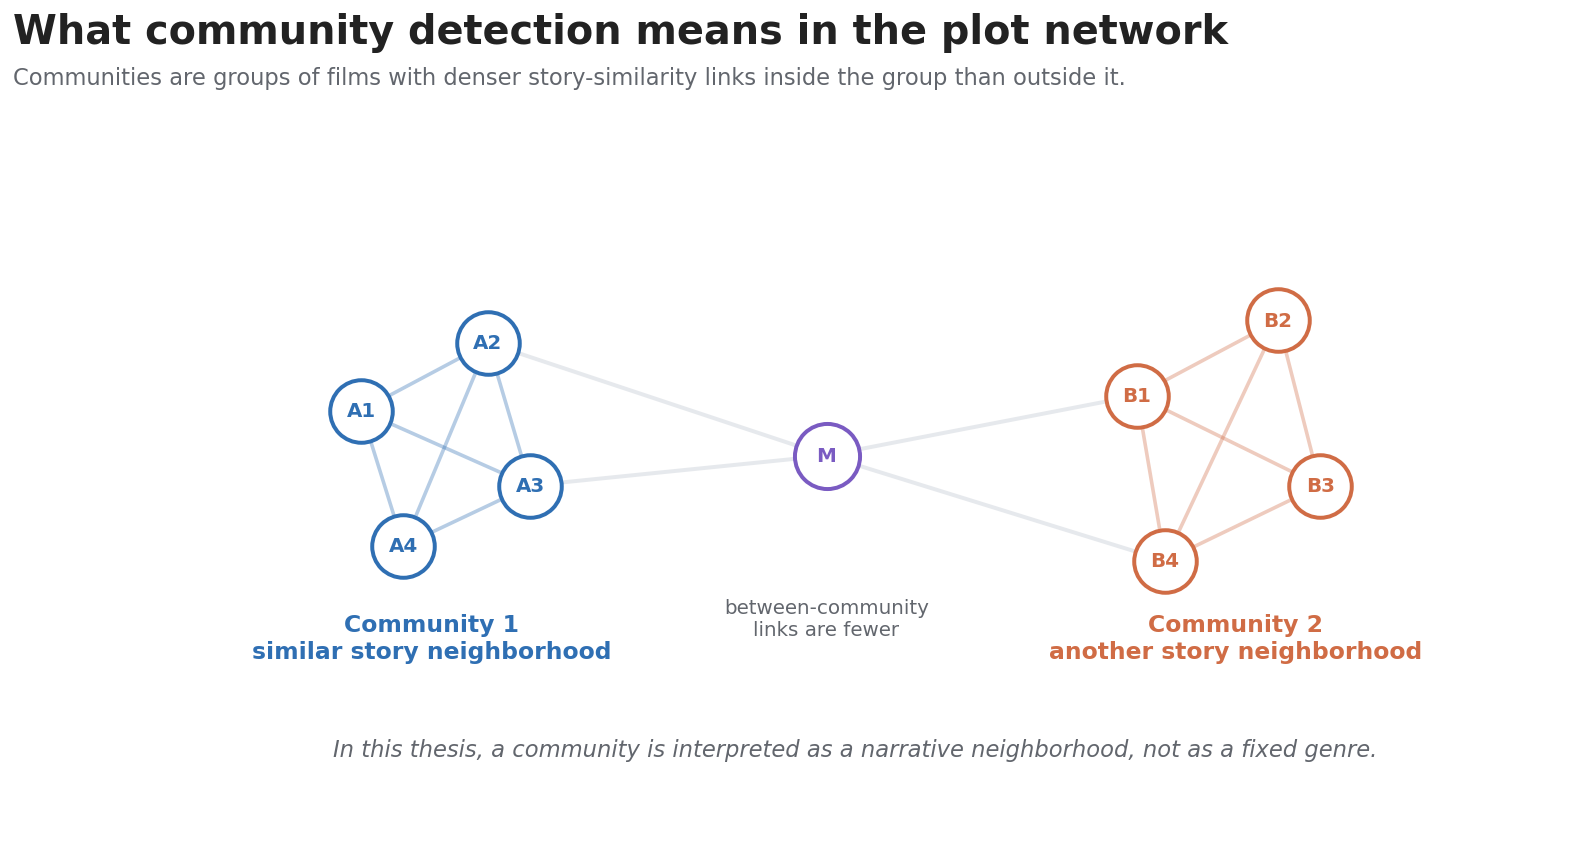

In [ ]:

fig, ax = plt.subplots(figsize=(14, 7.5))
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

title_block(
    fig,
    "What community detection means in the plot network",
    "Communities are groups of films with denser story-similarity links inside the group than outside it."
)

# toy communities positions
left = {
    "A1": (0.15, 0.58), "A2": (0.24, 0.67), "A3": (0.27, 0.48), "A4": (0.18, 0.40)
}
right = {
    "B1": (0.70, 0.60), "B2": (0.80, 0.70), "B3": (0.83, 0.48), "B4": (0.72, 0.38)
}
mid = {"M": (0.48, 0.52)}

def draw_group(group, color):
    keys = list(group.keys())
    # dense internal links
    for i in range(len(keys)):
        for j in range(i+1, len(keys)):
            x1, y1 = group[keys[i]]
            x2, y2 = group[keys[j]]
            ax.plot([x1, x2], [y1, y2], color=color, lw=2.0, alpha=0.35, zorder=1)
    for k, (x, y) in group.items():
        ax.scatter(x, y, s=1200, color="white", edgecolor=color, linewidth=2.2, zorder=3)
        ax.text(x, y, k, ha="center", va="center", fontsize=11, fontweight="bold", color=color, zorder=4)

draw_group(left, COL["blue"])
draw_group(right, COL["orange"])

# bridge/inter-community links
for a in ["A2", "A3"]:
    x1, y1 = left[a]
    x2, y2 = mid["M"]
    ax.plot([x1, x2], [y1, y2], color=COL["grid"], lw=2.2, alpha=0.9, zorder=1)

for b in ["B1", "B4"]:
    x1, y1 = right[b]
    x2, y2 = mid["M"]
    ax.plot([x1, x2], [y1, y2], color=COL["grid"], lw=2.2, alpha=0.9, zorder=1)

x, y = mid["M"]
ax.scatter(x, y, s=1300, color="white", edgecolor=COL["purple"], linewidth=2.2, zorder=3)
ax.text(x, y, "M", ha="center", va="center", fontsize=11, fontweight="bold", color=COL["purple"], zorder=4)

# labels
ax.text(0.20, 0.25, "Community 1\nsimilar story neighborhood", ha="center", fontsize=13, fontweight="bold", color=COL["blue"])
ax.text(0.77, 0.25, "Community 2\nanother story neighborhood", ha="center", fontsize=13, fontweight="bold", color=COL["orange"])
ax.text(0.48, 0.28, "between-community\nlinks are fewer", ha="center", fontsize=11, color=COL["muted"])

ax.text(
    0.5, 0.12,
    "In this thesis, a community is interpreted as a narrative neighborhood, not as a fixed genre.",
    ha="center",
    fontsize=12.5,
    color=COL["muted"],
    style="italic"
)

save_fig(fig, "01_community_detection_concept.png")
plt.show()


## 5. Figure 2 — Major communities lollipop

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/02_major_communities_lollipop.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/02_major_communities_lollipop.svg


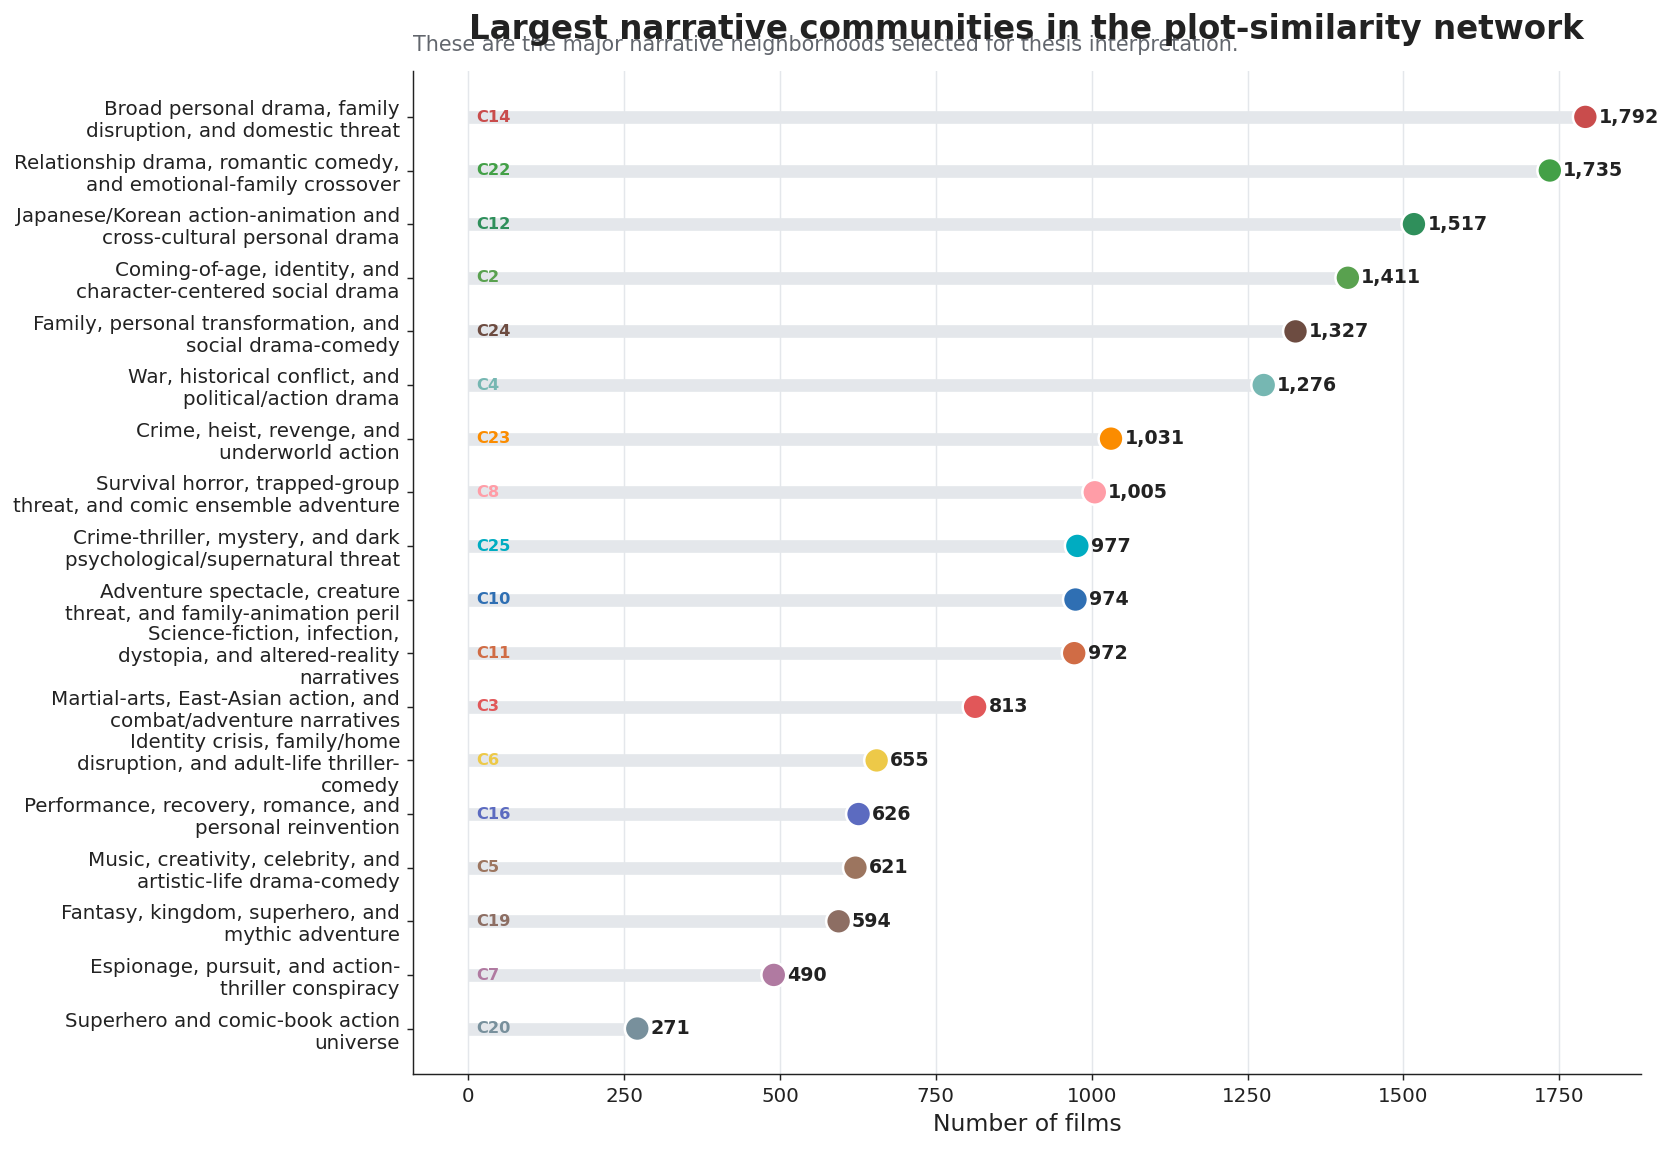

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/tables/02_major_communities_lollipop_data.csv


PosixPath('/content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/tables/02_major_communities_lollipop_data.csv')

In [ ]:

plot = profile.sort_values("n_films", ascending=True).tail(18).copy()

fig, ax = plt.subplots(figsize=(13, 9))
y = np.arange(len(plot))

ax.hlines(y, 0, plot["n_films"], color=COL["grid"], lw=7, zorder=1)
ax.scatter(
    plot["n_films"], y,
    s=190,
    c=[community_color(cid) for cid in plot["community_id"]],
    edgecolor="white",
    linewidth=1.4,
    zorder=3
)

for yi, (_, r) in zip(y, plot.iterrows()):
    ax.text(r["n_films"] + profile["n_films"].max()*0.012, yi, f"{int(r['n_films']):,}", va="center", fontsize=10.5, fontweight="bold")
    ax.text(12, yi, f"C{int(r['community_id'])}", va="center", fontsize=9, fontweight="bold", color=community_color(r["community_id"]))

ax.set_yticks(y)
ax.set_yticklabels([wrap_text(x, 36) for x in plot[label_col]])
ax.set_xlabel("Number of films")
ax.set_title("Largest narrative communities in the plot-similarity network", pad=18)
ax.text(
    0, 1.02,
    "These are the major narrative neighborhoods selected for thesis interpretation.",
    transform=ax.transAxes,
    fontsize=11.5,
    color=COL["muted"]
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=COL["grid"])
ax.set_axisbelow(True)

plt.tight_layout()
save_fig(fig, "02_major_communities_lollipop.png")
plt.show()

save_table(plot.sort_values("n_films", ascending=False), "02_major_communities_lollipop_data.csv")


## 6. Figure 3 — Major/minor community split

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/tables/03_major_minor_community_split_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/03_major_minor_community_split.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/03_major_minor_community_split.svg


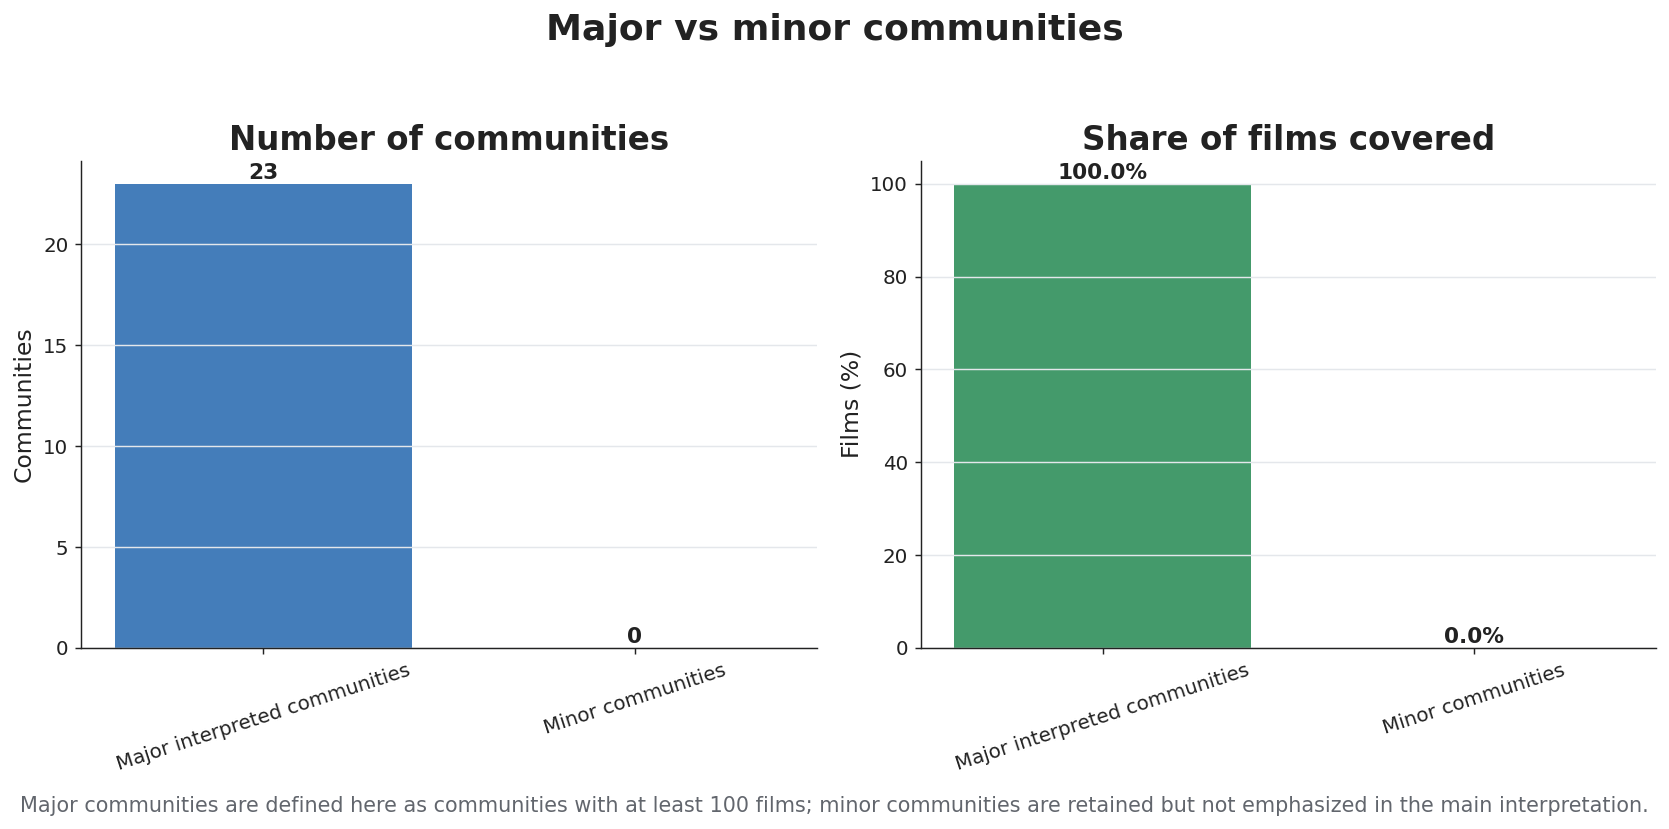

In [ ]:

major_n_films = profile.loc[profile["n_films"] >= major_threshold, "n_films"].sum()
minor_n_films = profile.loc[profile["n_films"] < major_threshold, "n_films"].sum()

split = pd.DataFrame([
    {"group": "Major interpreted communities", "n_communities": int((profile["n_films"] >= major_threshold).sum()), "n_films": int(major_n_films)},
    {"group": "Minor communities", "n_communities": int((profile["n_films"] < major_threshold).sum()), "n_films": int(minor_n_films)},
])
split["film_share_pct"] = split["n_films"] / split["n_films"].sum() * 100

save_table(split, "03_major_minor_community_split_table.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))

# Community count
axes[0].bar(split["group"], split["n_communities"], color=[COL["blue"], COL["grid"]], alpha=0.9)
axes[0].set_title("Number of communities")
axes[0].set_ylabel("Communities")
for i, r in split.iterrows():
    axes[0].text(i, r["n_communities"] + 0.25, f"{int(r['n_communities'])}", ha="center", fontweight="bold")
axes[0].tick_params(axis="x", rotation=18)
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].grid(axis="y", color=COL["grid"])

# Film coverage
axes[1].bar(split["group"], split["film_share_pct"], color=[COL["green"], COL["grid"]], alpha=0.9)
axes[1].set_title("Share of films covered")
axes[1].set_ylabel("Films (%)")
for i, r in split.iterrows():
    axes[1].text(i, r["film_share_pct"] + 1, f"{r['film_share_pct']:.1f}%", ha="center", fontweight="bold")
axes[1].tick_params(axis="x", rotation=18)
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].grid(axis="y", color=COL["grid"])

fig.suptitle("Major vs minor communities", fontsize=20, fontweight="bold", y=1.04)
fig.text(
    0.5, -0.02,
    f"Major communities are defined here as communities with at least {major_threshold} films; minor communities are retained but not emphasized in the main interpretation.",
    ha="center",
    fontsize=11.5,
    color=COL["muted"]
)

plt.tight_layout()
save_fig(fig, "03_major_minor_community_split.png")
plt.show()


## 7. Figure 4 — Top communities index table

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/tables/04_top_communities_index_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/04_top_communities_index_table.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/04_top_communities_index_table.svg


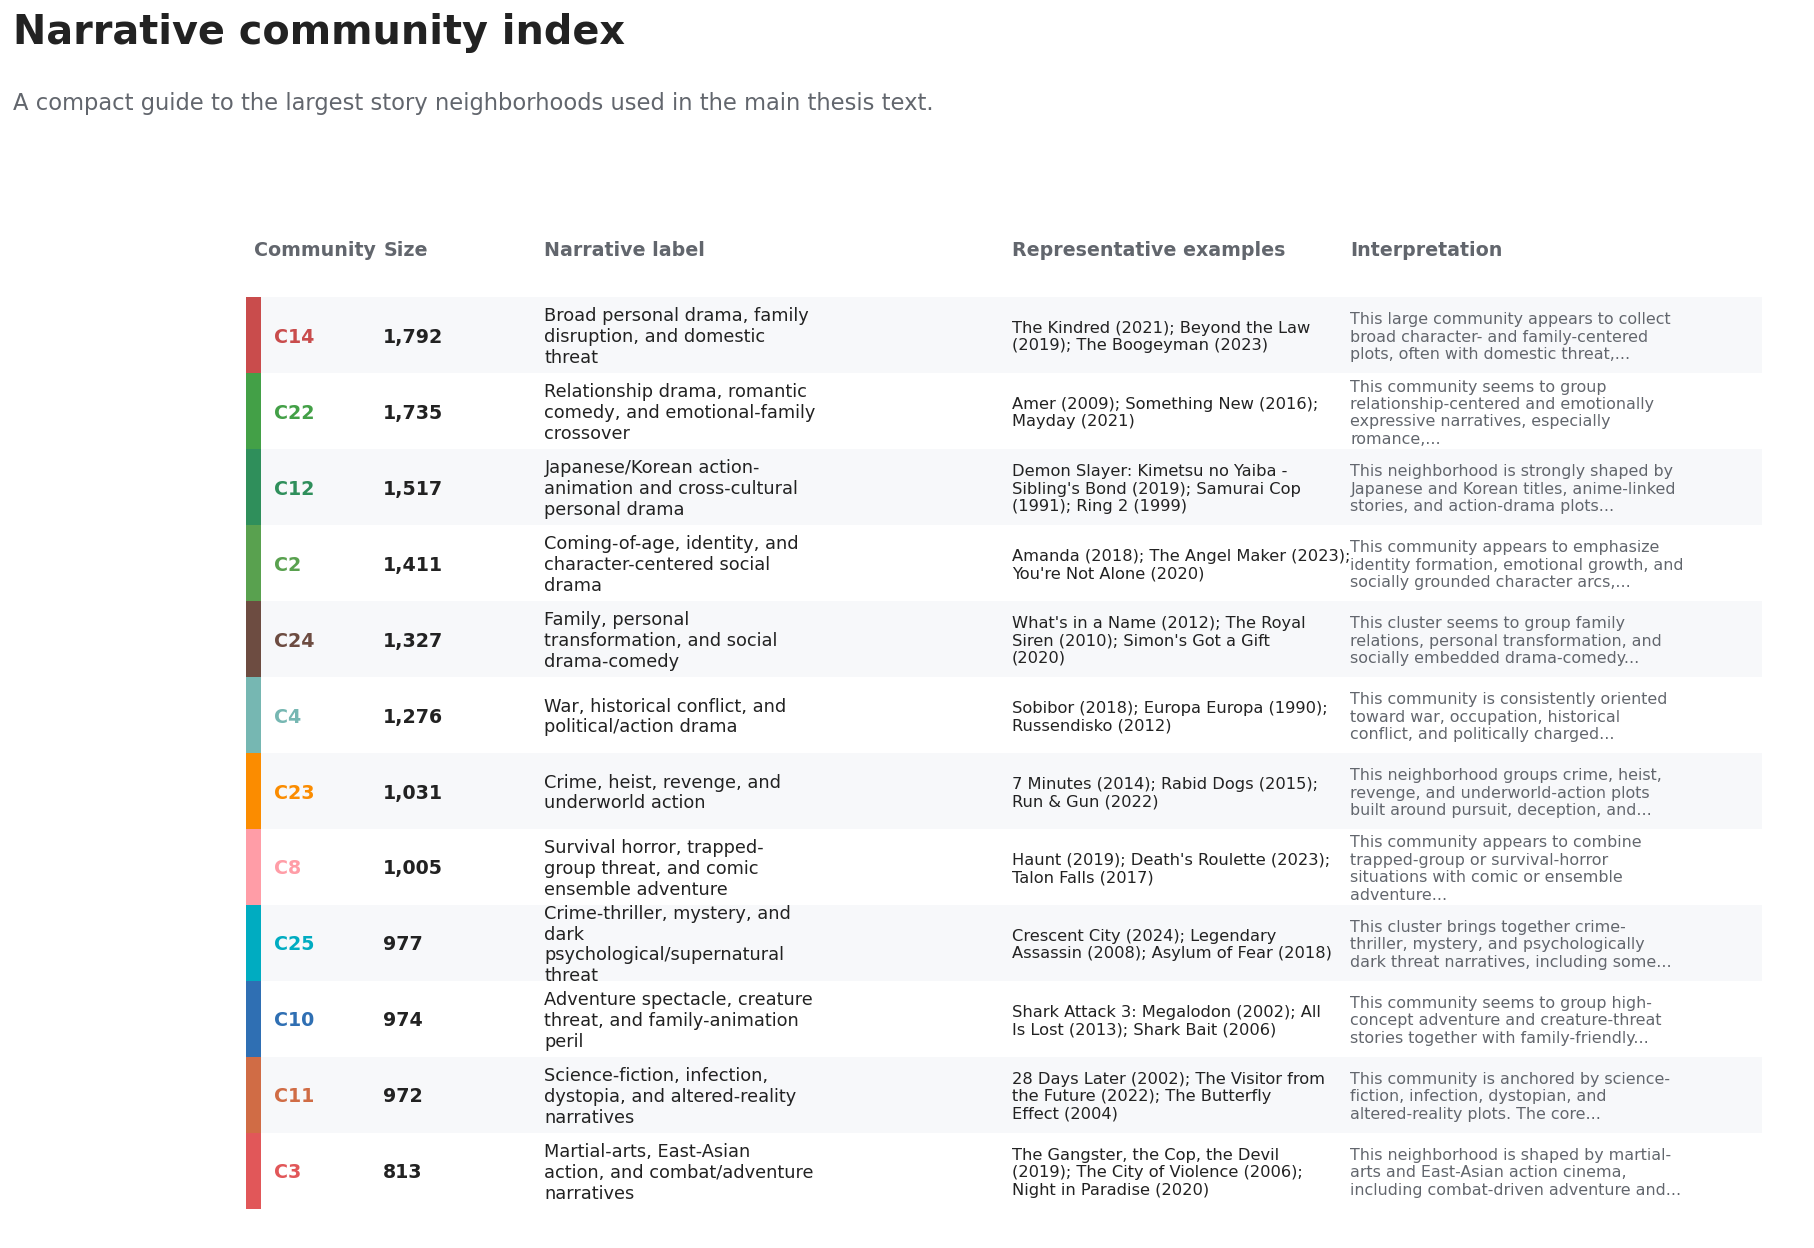

In [ ]:

top_index = profile.sort_values("n_films", ascending=False).head(12).copy()

index_rows = []
for _, r in top_index.iterrows():
    examples = r.get("selected_examples", "")
    index_rows.append({
        "community": f"C{int(r['community_id'])}",
        "size": f"{int(r['n_films']):,}",
        "narrative_label": str(r[label_col]),
        "examples": examples,
        "interpretation": str(r.get(note_col, "")),
        "color": community_color(r["community_id"])
    })

index_tbl = pd.DataFrame(index_rows)
save_table(index_tbl.drop(columns=["color"]), "04_top_communities_index_table.csv")

fig, ax = plt.subplots(figsize=(16, 11))
ax.axis("off")
title_block(
    fig,
    "Narrative community index",
    "A compact guide to the largest story neighborhoods used in the main thesis text.",
    x=0.04,
    y=0.965
)

start_y = 0.84
row_h = 0.069
xs = [0.04, 0.12, 0.22, 0.51, 0.72]
headers = ["Community", "Size", "Narrative label", "Representative examples", "Interpretation"]

for x, h in zip(xs, headers):
    ax.text(x, start_y + 0.050, h, transform=ax.transAxes, fontsize=10.5, fontweight="bold", color=COL["muted"])

for i, r in index_tbl.iterrows():
    y = start_y - i * row_h
    bg = COL["panel"] if i % 2 == 0 else "white"
    ax.add_patch(patches.Rectangle((0.035, y - row_h + 0.012), 0.94, row_h, transform=ax.transAxes, facecolor=bg, edgecolor="none"))
    ax.add_patch(patches.Rectangle((0.035, y - row_h + 0.012), 0.009, row_h, transform=ax.transAxes, facecolor=r["color"], edgecolor="none"))

    ax.text(0.052, y - 0.024, r["community"], transform=ax.transAxes, fontsize=10.5, fontweight="bold", color=r["color"], va="center")
    ax.text(0.12, y - 0.024, r["size"], transform=ax.transAxes, fontsize=10.5, fontweight="bold", va="center")
    ax.text(0.22, y - 0.024, wrap_text(r["narrative_label"], 29), transform=ax.transAxes, fontsize=9.8, va="center")
    ax.text(0.51, y - 0.024, wrap_text(shorten(r["examples"], 95), 38), transform=ax.transAxes, fontsize=9.0, va="center")
    ax.text(0.72, y - 0.024, wrap_text(shorten(r["interpretation"], 115), 41), transform=ax.transAxes, fontsize=8.8, color=COL["muted"], va="center")

save_fig(fig, "04_top_communities_index_table.png")
plt.show()


## 8. Figure 5 — Individual community profile sheets

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C14.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C14.svg


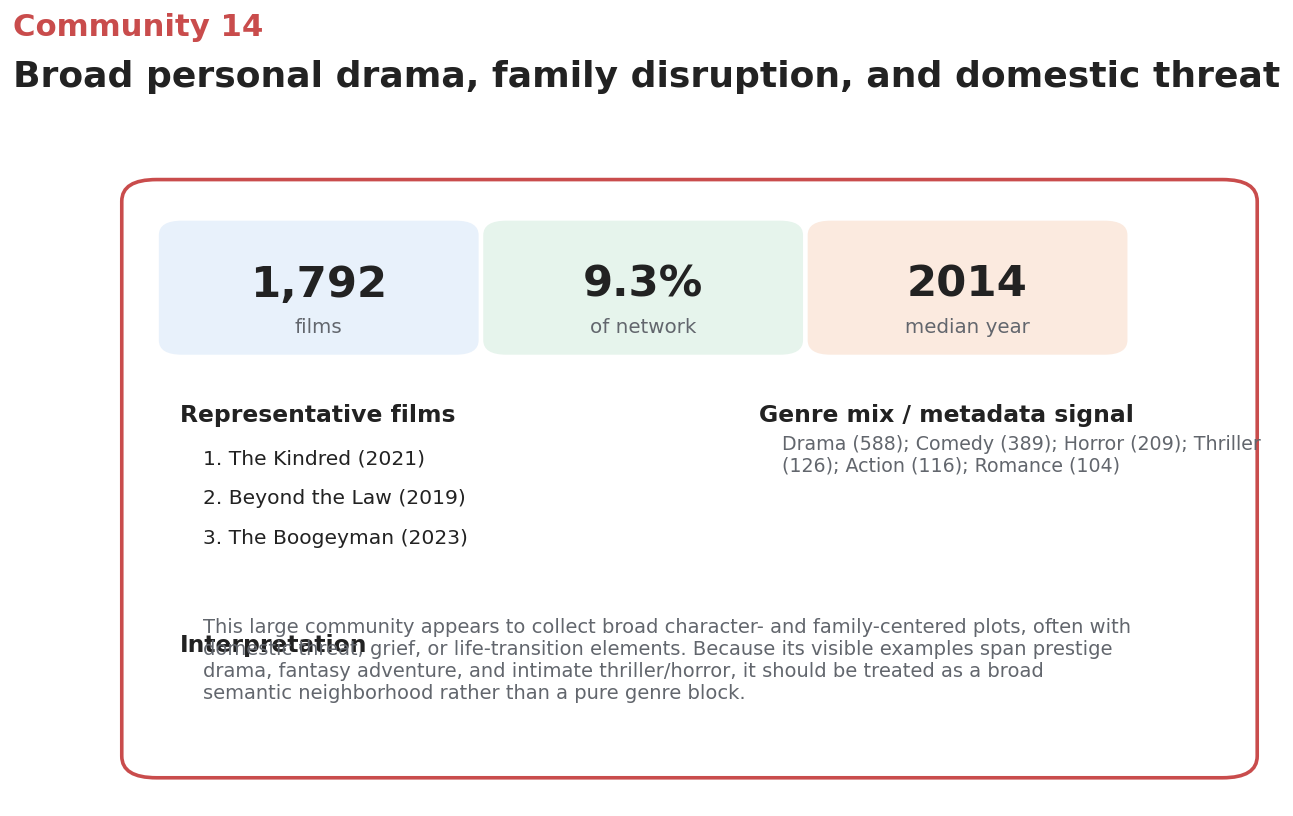

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C22.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C22.svg


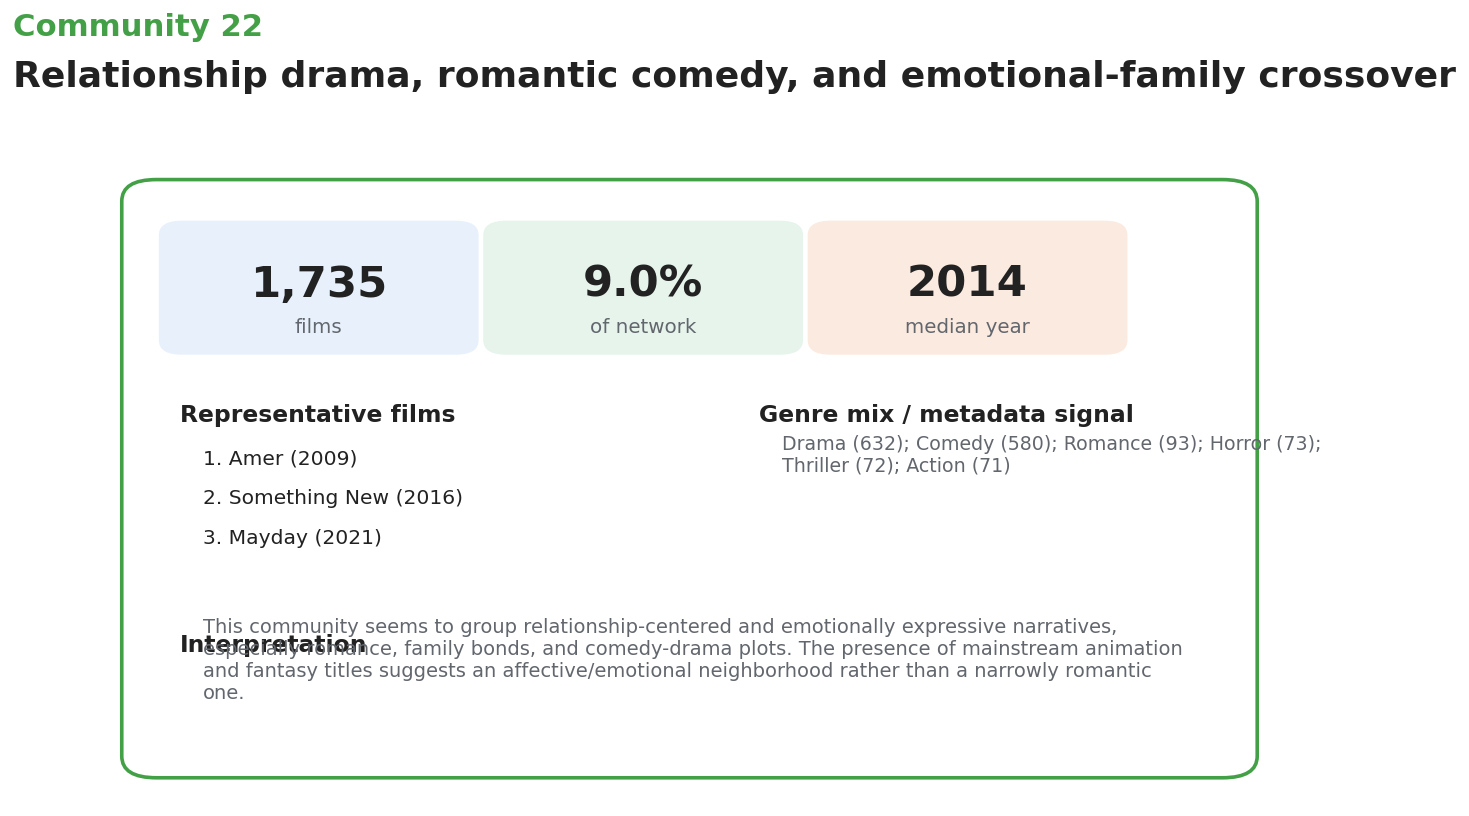

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C12.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C12.svg


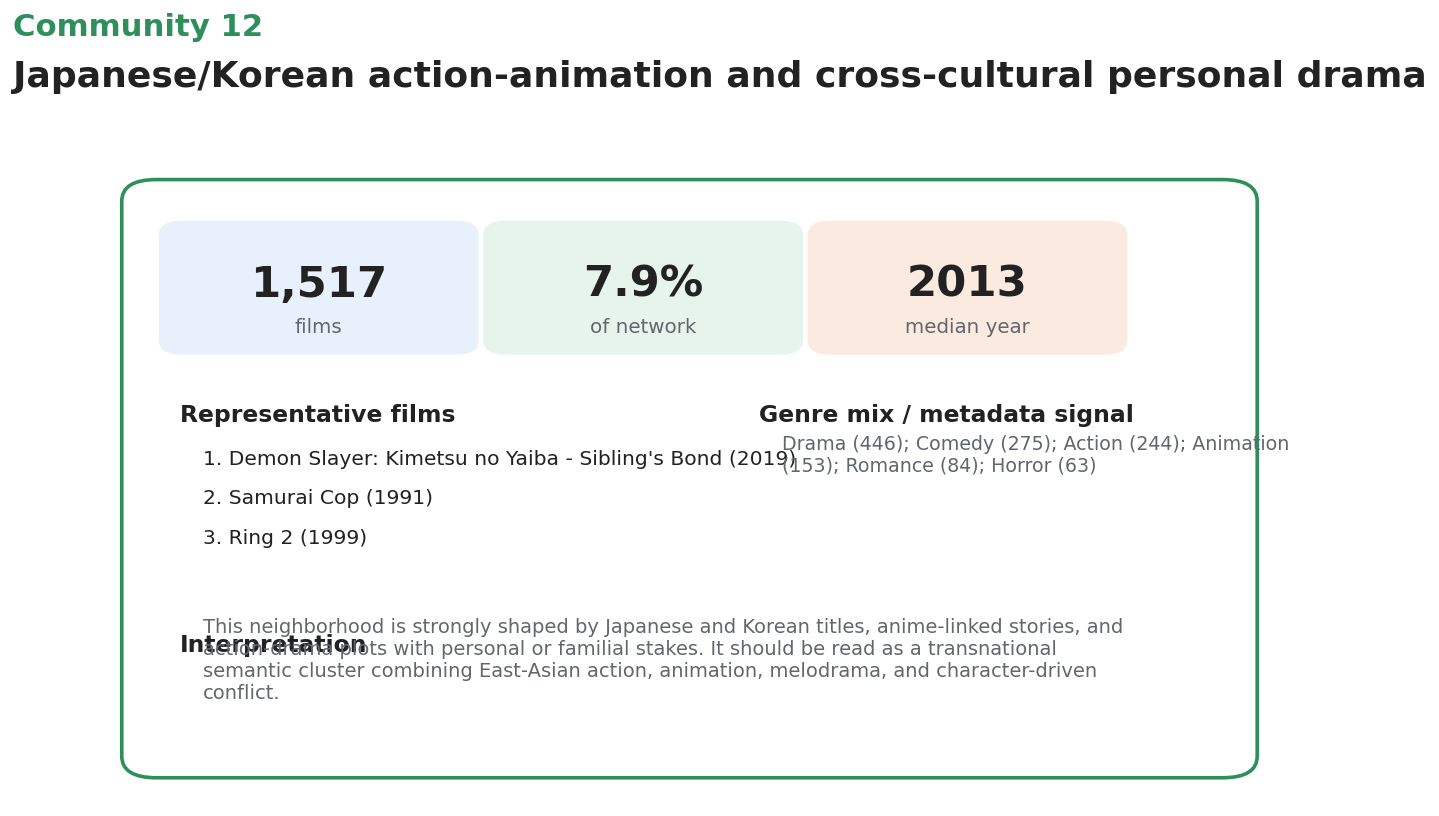

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C02.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C02.svg


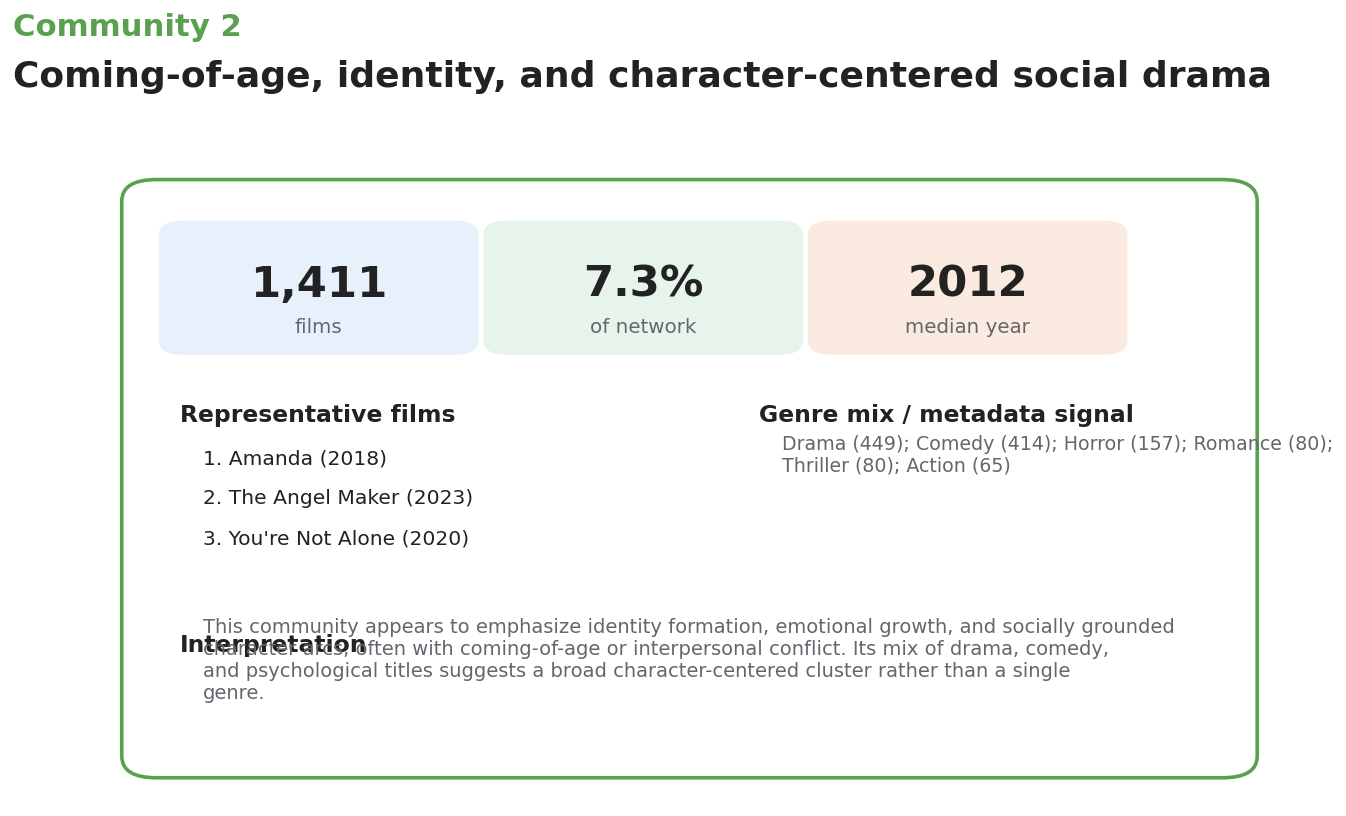

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C24.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C24.svg


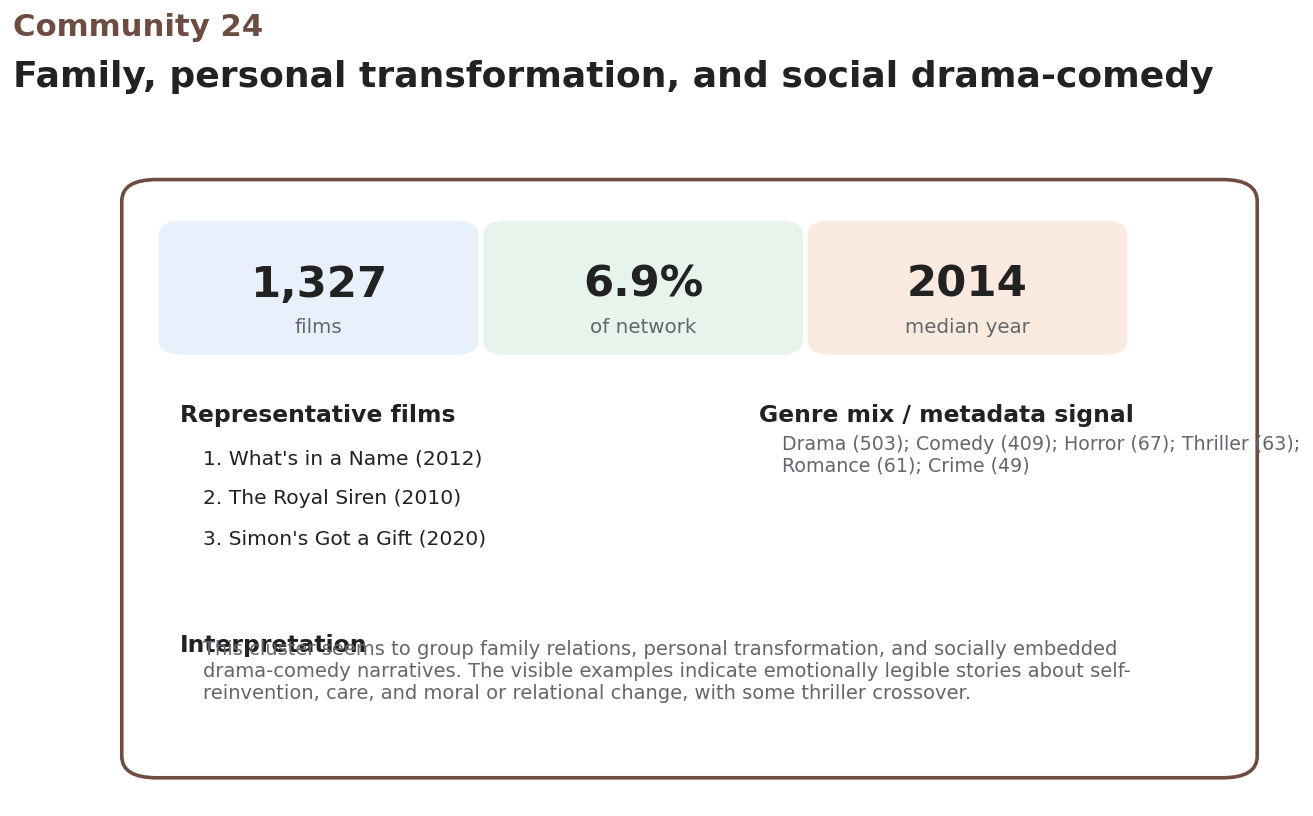

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C04.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C04.svg


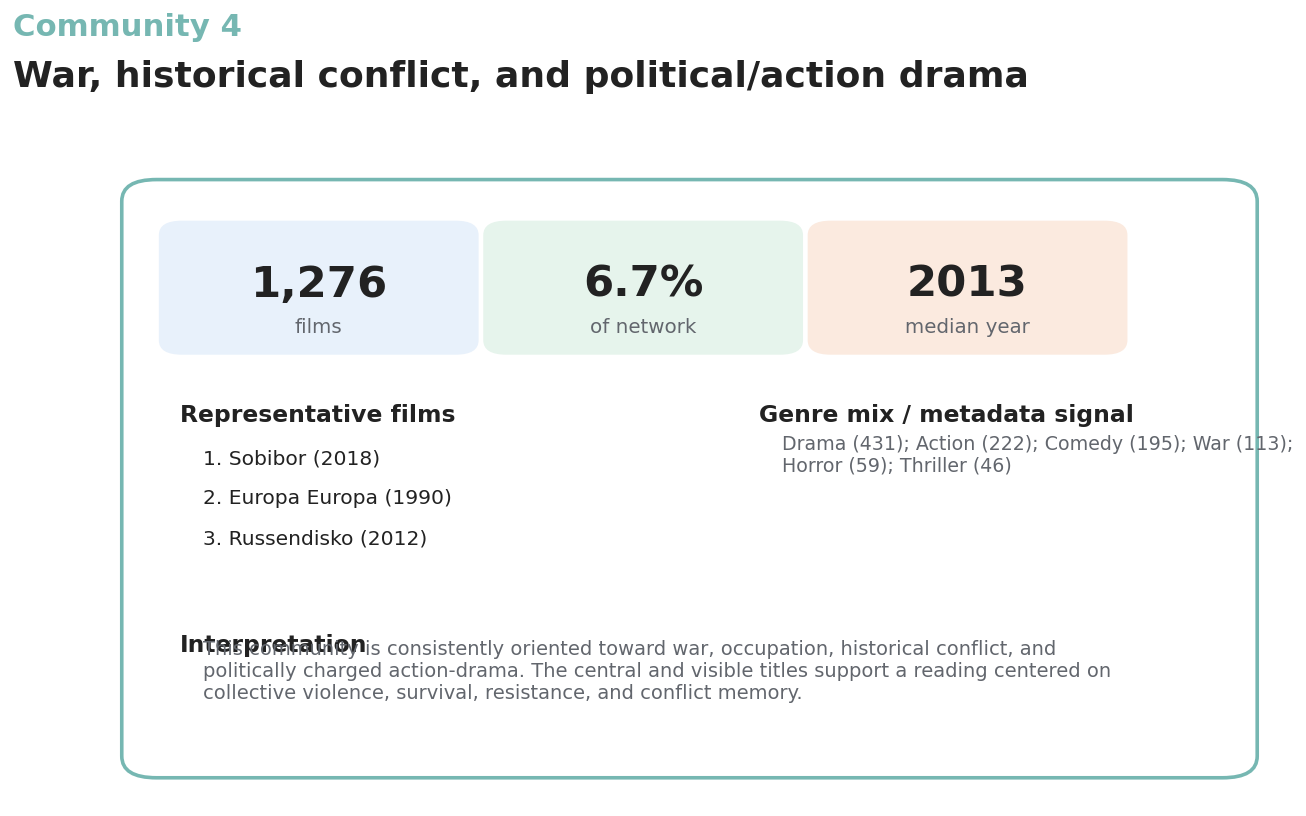

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C23.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C23.svg


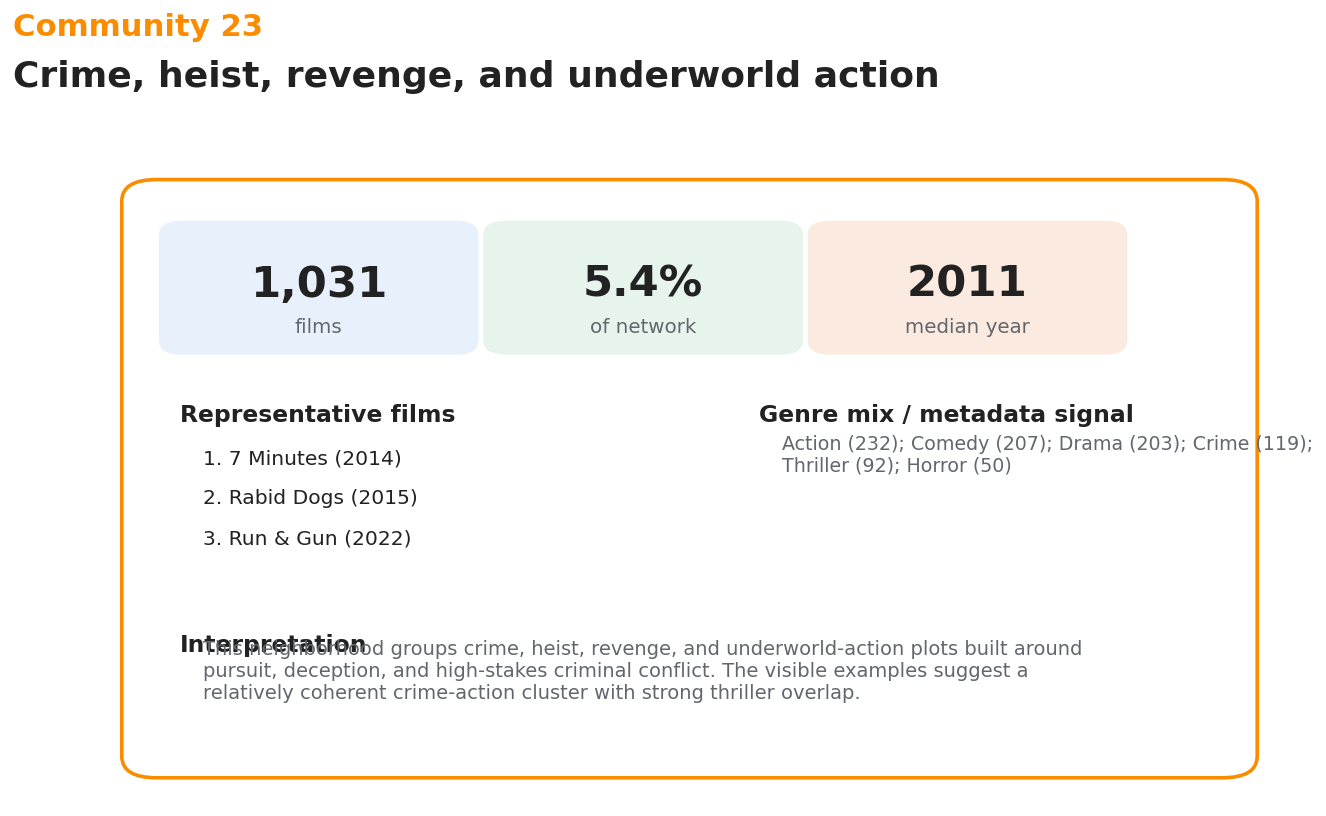

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C08.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/05_community_profile_sheet_C08.svg


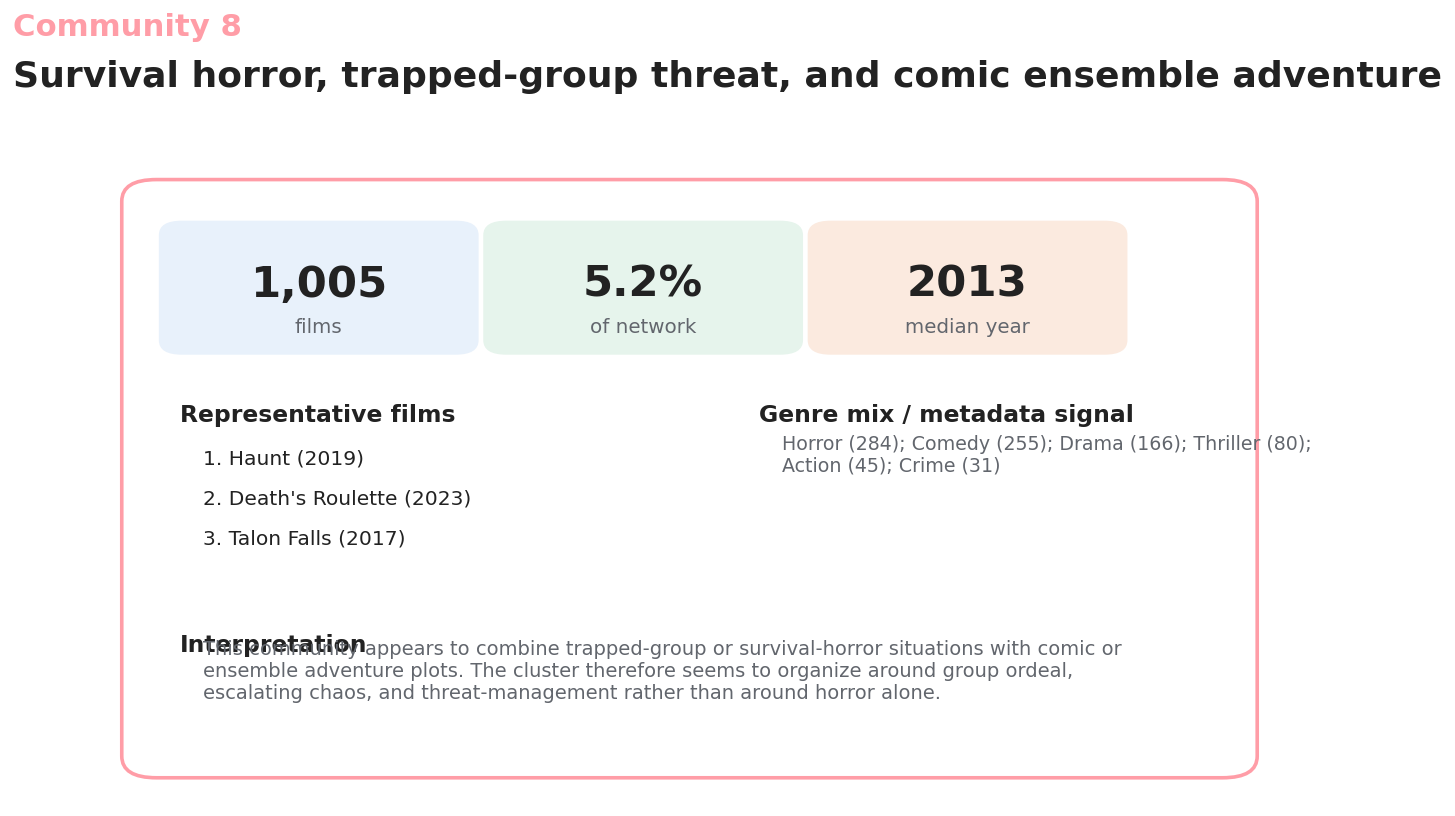

In [ ]:

# Create one page per top community. These are for main text selection or appendix.
top_profiles = profile.sort_values("n_films", ascending=False).head(8).copy()

for _, r in top_profiles.iterrows():
    cid = int(r["community_id"])
    color = community_color(cid)
    label = str(r[label_col])
    examples = r.get("selected_examples", "")
    interpretation = str(r.get(note_col, ""))
    top_genres = first_available(r, ["top_primary_genres", "top_genres"])

    fig, ax = plt.subplots(figsize=(11.5, 7.2))
    ax.axis("off")

    # Header
    fig.text(0.06, 0.93, f"Community {cid}", fontsize=17, fontweight="bold", color=color, ha="left")
    fig.text(0.06, 0.875, wrap_text(label, 72), fontsize=20, fontweight="bold", color=COL["ink"], ha="left")

    # Size card
    ax.add_patch(FancyBboxPatch(
        (0.06, 0.64), 0.24, 0.15,
        boxstyle="round,pad=0.018,rounding_size=0.02",
        facecolor=COL["light_blue"],
        edgecolor="none",
        transform=ax.transAxes
    ))
    ax.text(0.18, 0.72, f"{int(r['n_films']):,}", transform=ax.transAxes, ha="center", va="center", fontsize=24, fontweight="bold")
    ax.text(0.18, 0.66, "films", transform=ax.transAxes, ha="center", va="center", fontsize=11, color=COL["muted"])

    # Share card
    share = r.get("share_of_network_pct", np.nan)
    ax.add_patch(FancyBboxPatch(
        (0.34, 0.64), 0.24, 0.15,
        boxstyle="round,pad=0.018,rounding_size=0.02",
        facecolor=COL["light_green"],
        edgecolor="none",
        transform=ax.transAxes
    ))
    ax.text(0.46, 0.72, f"{float(share):.1f}%" if pd.notna(share) else "—", transform=ax.transAxes, ha="center", va="center", fontsize=24, fontweight="bold")
    ax.text(0.46, 0.66, "of network", transform=ax.transAxes, ha="center", va="center", fontsize=11, color=COL["muted"])

    # Years card
    median_year = r.get("median_year", np.nan)
    ax.add_patch(FancyBboxPatch(
        (0.62, 0.64), 0.24, 0.15,
        boxstyle="round,pad=0.018,rounding_size=0.02",
        facecolor=COL["light_orange"],
        edgecolor="none",
        transform=ax.transAxes
    ))
    ax.text(0.74, 0.72, f"{int(median_year)}" if pd.notna(median_year) else "—", transform=ax.transAxes, ha="center", va="center", fontsize=24, fontweight="bold")
    ax.text(0.74, 0.66, "median year", transform=ax.transAxes, ha="center", va="center", fontsize=11, color=COL["muted"])

    # Examples
    ax.text(0.06, 0.53, "Representative films", transform=ax.transAxes, fontsize=13, fontweight="bold", color=COL["ink"])
    ex_list = parse_examples(examples, max_n=5)
    y = 0.47
    for i, ex in enumerate(ex_list, start=1):
        ax.text(0.08, y, f"{i}. {shorten(ex, 75)}", transform=ax.transAxes, fontsize=11.2, color=COL["ink"])
        y -= 0.055

    # Interpretation
    ax.text(0.06, 0.21, "Interpretation", transform=ax.transAxes, fontsize=13, fontweight="bold", color=COL["ink"])
    ax.text(0.08, 0.145, wrap_text(shorten(interpretation, 370), 95), transform=ax.transAxes, fontsize=10.8, color=COL["muted"])

    # Genre note if exists
    if top_genres:
        ax.text(0.56, 0.53, "Genre mix / metadata signal", transform=ax.transAxes, fontsize=13, fontweight="bold", color=COL["ink"])
        ax.text(0.58, 0.46, wrap_text(shorten(top_genres, 210), 55), transform=ax.transAxes, fontsize=10.5, color=COL["muted"])

    # Border
    ax.add_patch(FancyBboxPatch(
        (0.035, 0.06), 0.93, 0.78,
        boxstyle="round,pad=0.025,rounding_size=0.03",
        facecolor="none",
        edgecolor=color,
        linewidth=2.0,
        transform=ax.transAxes
    ))

    save_fig(fig, f"05_community_profile_sheet_C{cid:02d}.png")
    plt.show()


## 9. Figure 6 — Representative films gallery

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/06_representative_films_gallery.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/06_representative_films_gallery.svg


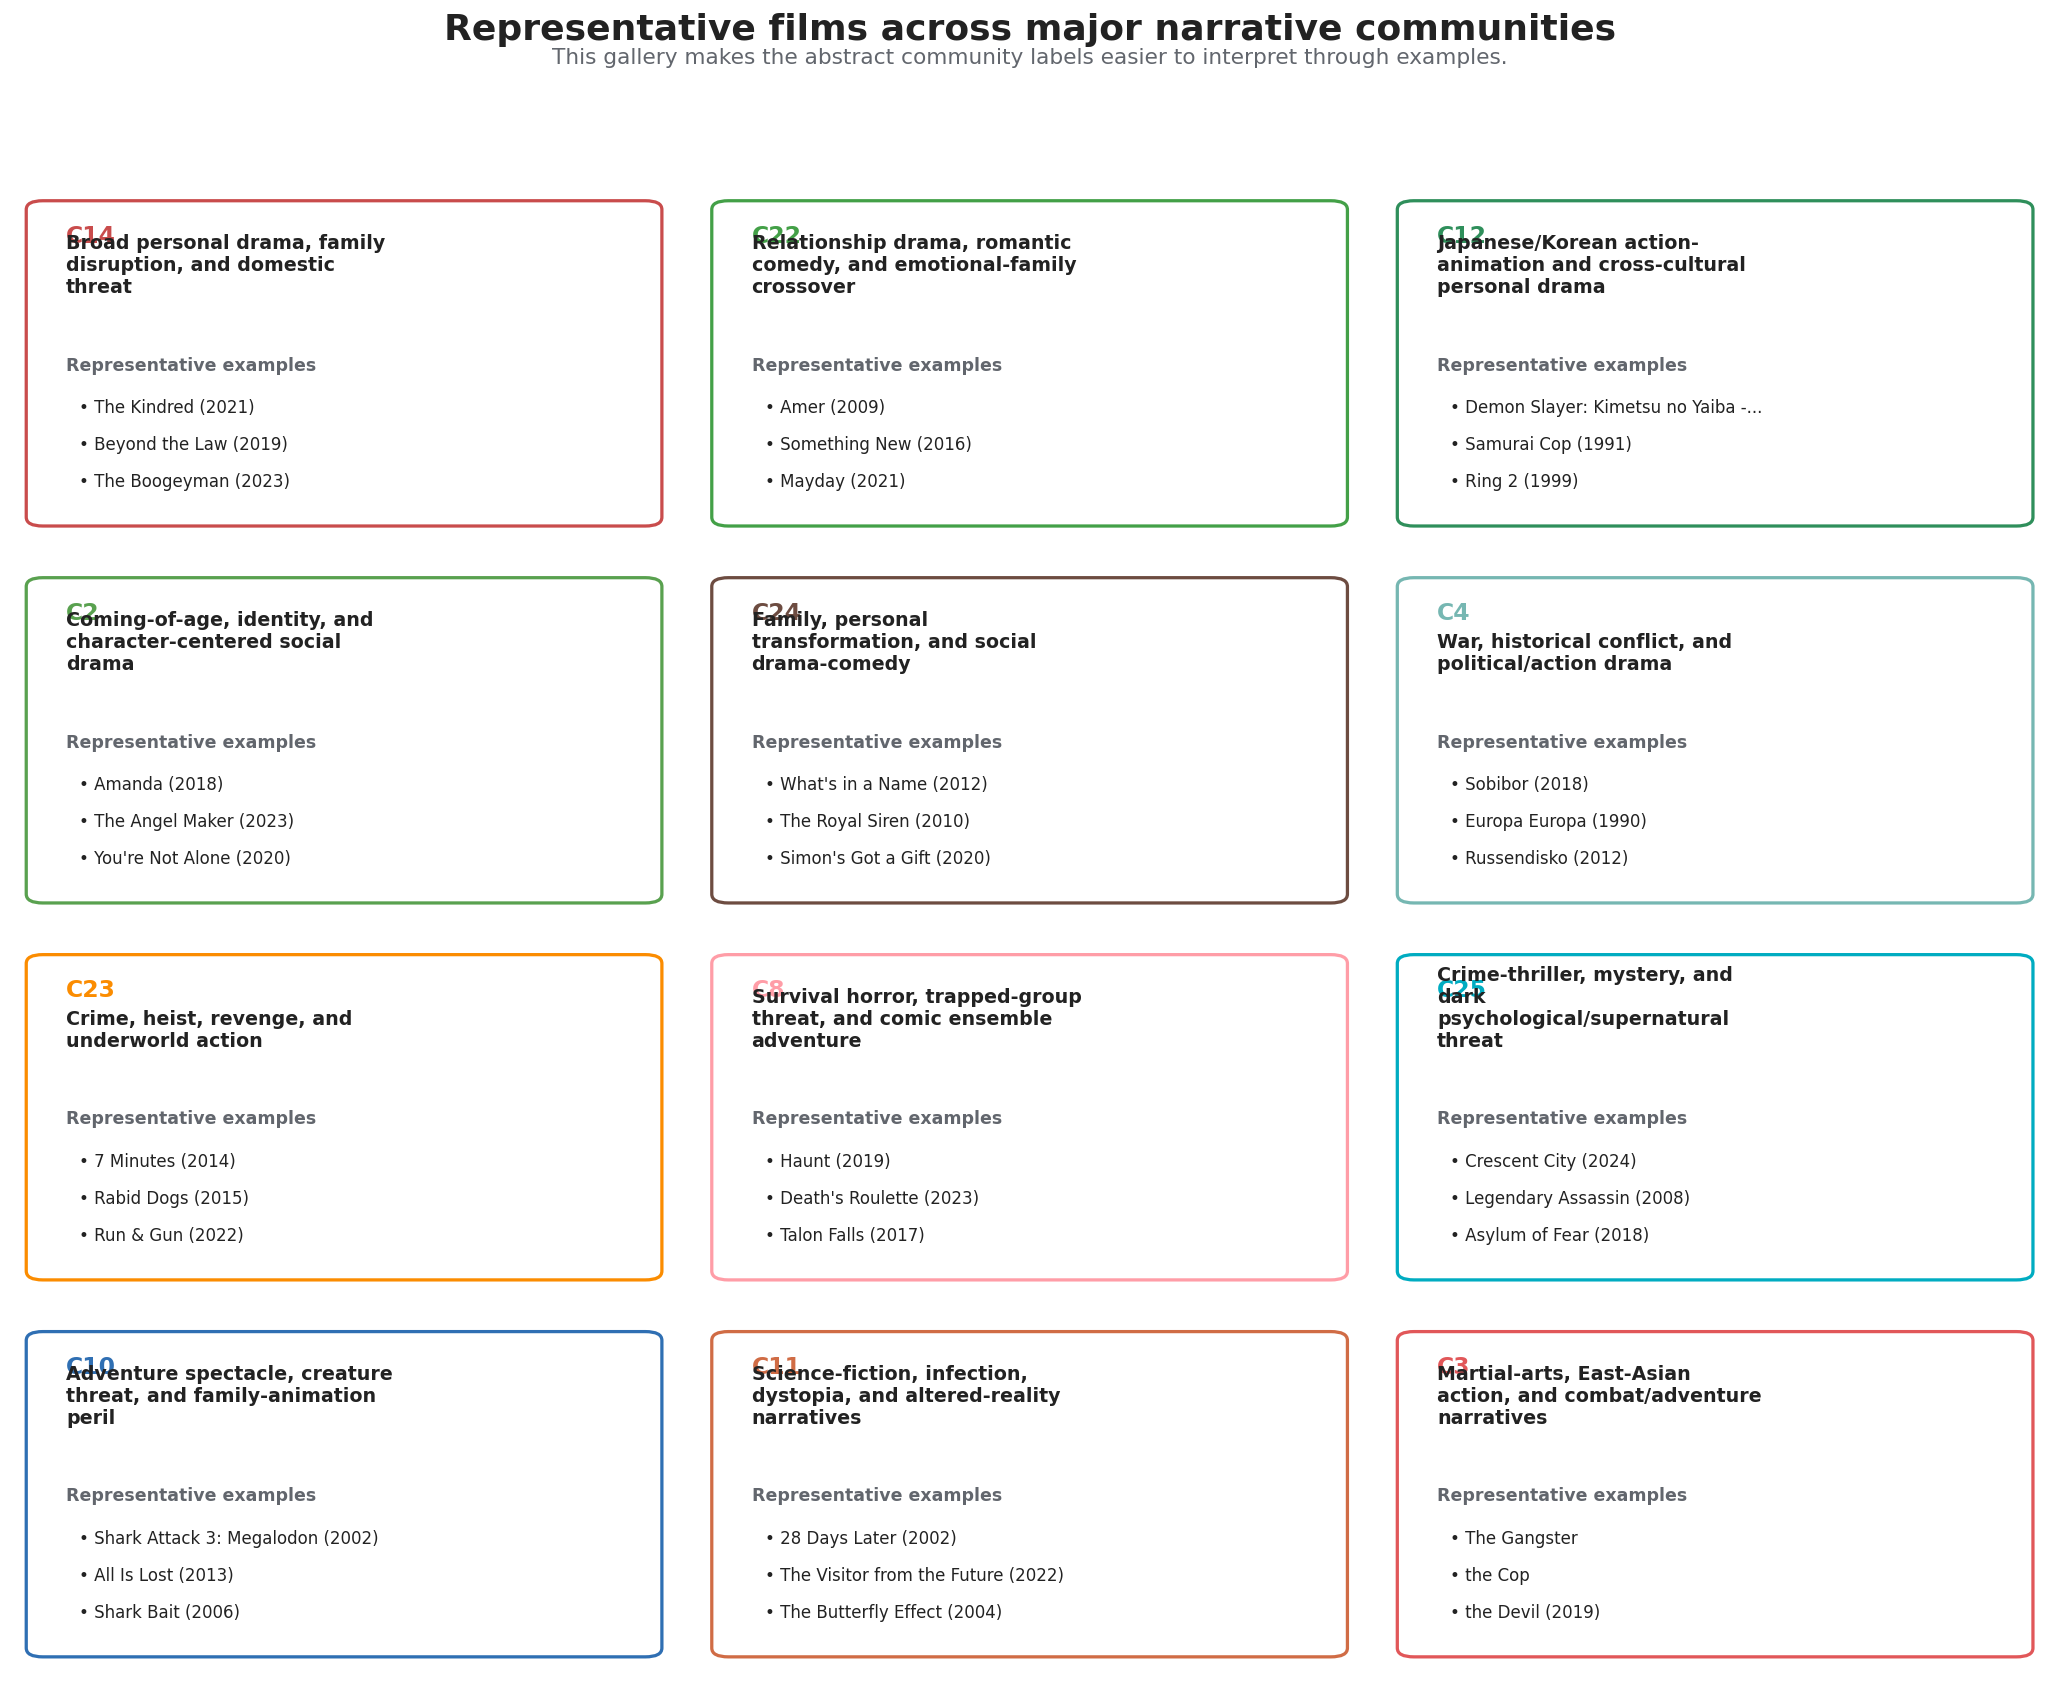

In [ ]:

# Create gallery using the top 12 communities with up to 3 examples each.
gallery = profile.sort_values("n_films", ascending=False).head(12).copy()

fig, axes = plt.subplots(4, 3, figsize=(16, 13))
axes = axes.ravel()

for ax, (_, r) in zip(axes, gallery.iterrows()):
    ax.axis("off")
    cid = int(r["community_id"])
    color = community_color(cid)
    label = str(r[label_col])
    examples = parse_examples(r.get("selected_examples", ""), max_n=3)

    ax.add_patch(FancyBboxPatch(
        (0.04, 0.06), 0.92, 0.88,
        boxstyle="round,pad=0.020,rounding_size=0.025",
        facecolor="white",
        edgecolor=color,
        linewidth=1.8,
        transform=ax.transAxes
    ))
    ax.text(0.08, 0.84, f"C{cid}", transform=ax.transAxes, fontsize=13, fontweight="bold", color=color)
    ax.text(0.08, 0.70, wrap_text(label, 30), transform=ax.transAxes, fontsize=10.5, fontweight="bold")
    ax.text(0.08, 0.48, "Representative examples", transform=ax.transAxes, fontsize=9.6, color=COL["muted"], fontweight="bold")

    y = 0.36
    for ex in examples:
        ax.text(0.10, y, "• " + shorten(ex, 42), transform=ax.transAxes, fontsize=9.2, color=COL["ink"])
        y -= 0.105

for ax in axes[len(gallery):]:
    ax.axis("off")

fig.suptitle("Representative films across major narrative communities", fontsize=20, fontweight="bold", y=0.995)
fig.text(0.5, 0.965, "This gallery makes the abstract community labels easier to interpret through examples.", ha="center", fontsize=12, color=COL["muted"])

plt.tight_layout(rect=[0, 0, 1, 0.94])
save_fig(fig, "06_representative_films_gallery.png")
plt.show()


## 10. Figure 7 — Community size vs median year

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/07_community_size_vs_median_year.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/07_community_size_vs_median_year.svg


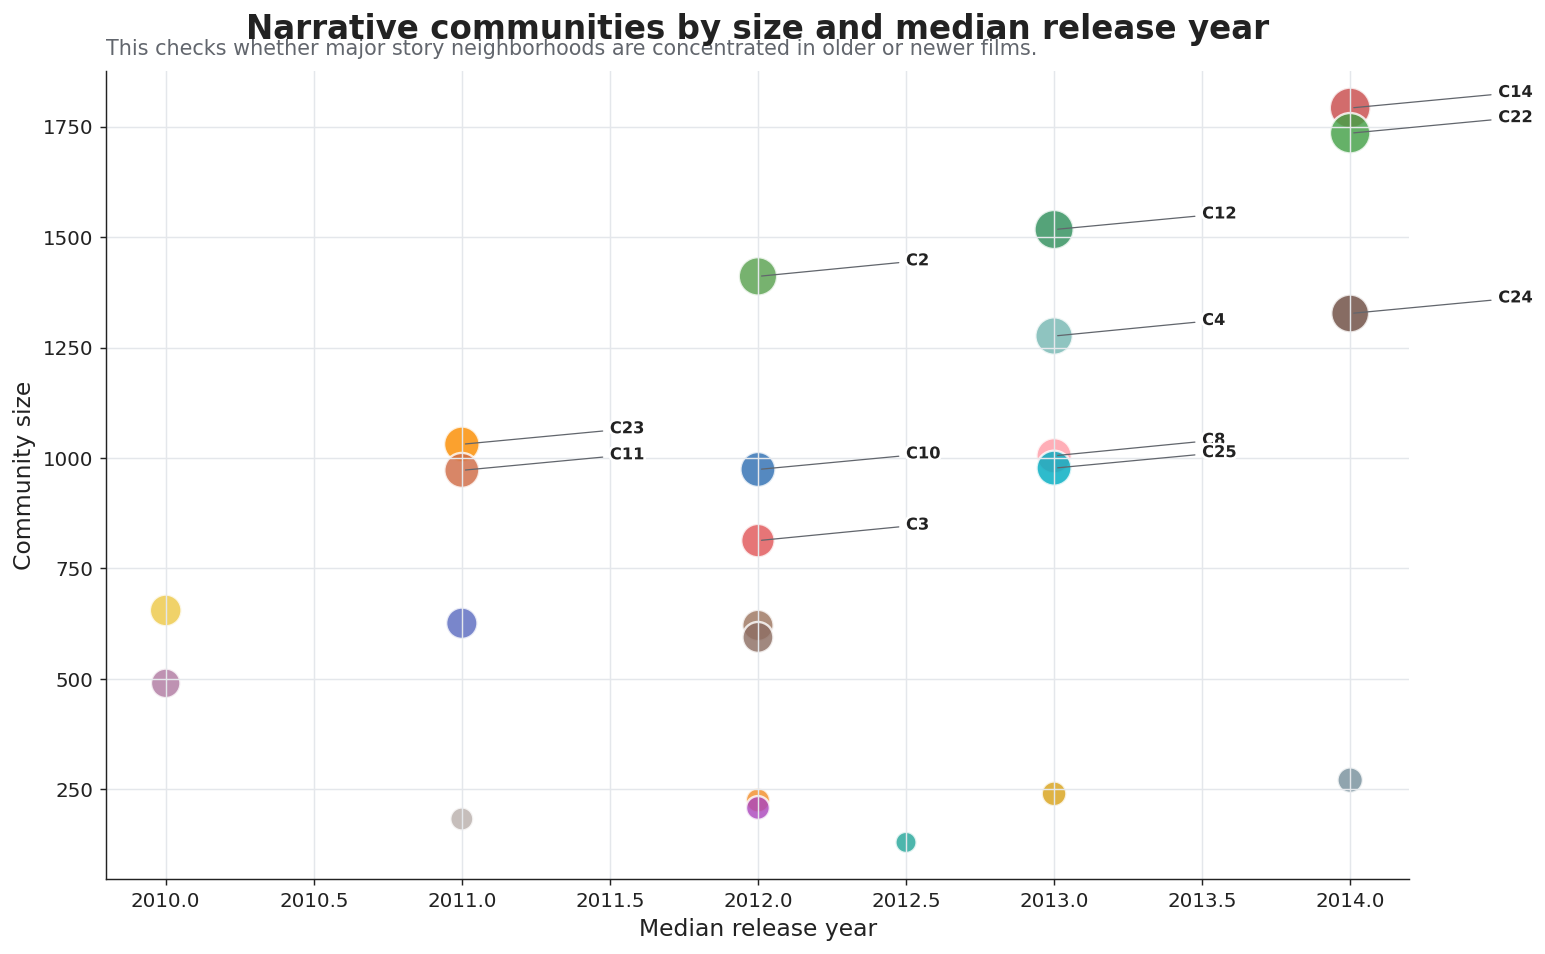

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/tables/07_community_size_vs_median_year_data.csv


In [ ]:

if "median_year" in profile.columns and profile["median_year"].notna().any():
    plot = profile.dropna(subset=["median_year", "n_films"]).copy()
    plot = plot.sort_values("n_films", ascending=False).head(23)

    fig, ax = plt.subplots(figsize=(12, 7.5))
    sizes = np.sqrt(plot["n_films"]) * 12

    ax.scatter(
        plot["median_year"],
        plot["n_films"],
        s=sizes,
        c=[community_color(cid) for cid in plot["community_id"]],
        alpha=0.82,
        edgecolor="white",
        linewidth=1.3
    )

    for _, r in plot.sort_values("n_films", ascending=False).head(12).iterrows():
        ax.annotate(
            f"C{int(r['community_id'])}",
            xy=(r["median_year"], r["n_films"]),
            xytext=(r["median_year"] + 0.5, r["n_films"] + 25),
            fontsize=9,
            fontweight="bold",
            arrowprops=dict(arrowstyle="-", color=COL["muted"], lw=0.7),
            path_effects=[pe.withStroke(linewidth=3, foreground="white")]
        )

    ax.set_title("Narrative communities by size and median release year", pad=18)
    ax.text(
        0, 1.02,
        "This checks whether major story neighborhoods are concentrated in older or newer films.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.set_xlabel("Median release year")
    ax.set_ylabel("Community size")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color=COL["grid"])

    plt.tight_layout()
    save_fig(fig, "07_community_size_vs_median_year.png")
    plt.show()

    save_table(plot, "07_community_size_vs_median_year_data.csv")
else:
    print("Median year not available.")


## 11. Figure 8 — Genre mix small multiples

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/08_community_genre_mix_small_multiples.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/08_community_genre_mix_small_multiples.svg


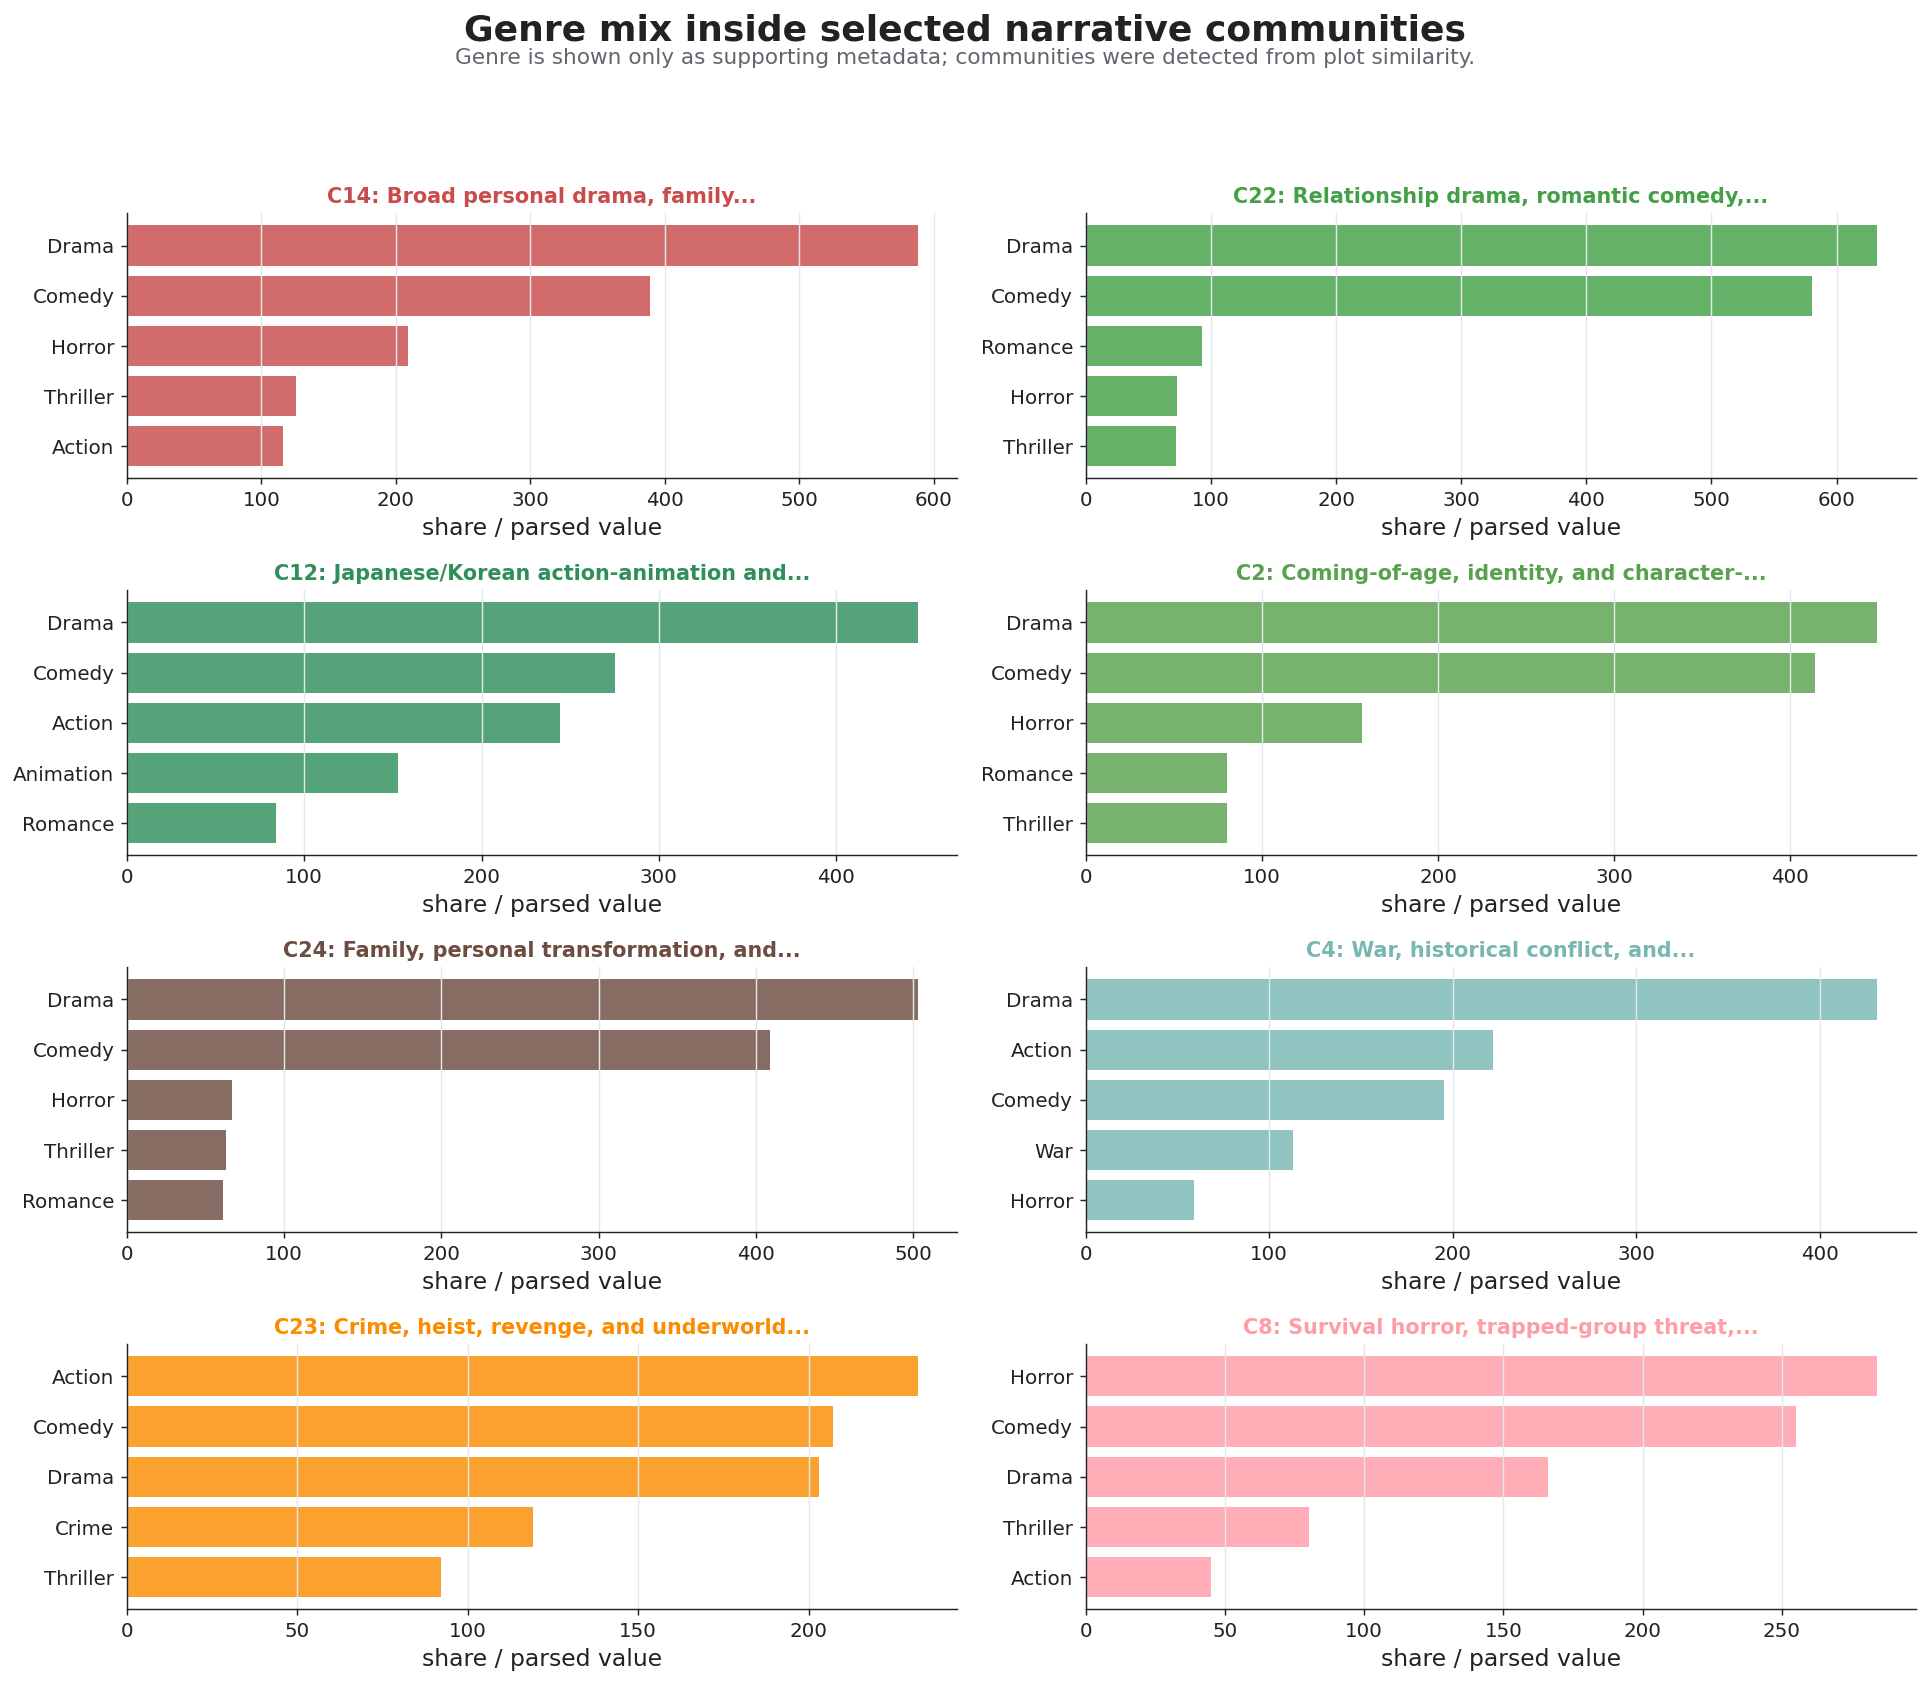

In [ ]:

# This uses genre mix only as metadata support, not as the basis of communities.
genre_col = None
for c in ["top_primary_genres", "top_genres"]:
    if c in profile.columns:
        genre_col = c
        break

if genre_col:
    top = profile.sort_values("n_films", ascending=False).head(8).copy()

    fig, axes = plt.subplots(4, 2, figsize=(15, 13))
    axes = axes.ravel()

    for ax, (_, r) in zip(axes, top.iterrows()):
        cid = int(r["community_id"])
        label = str(r[label_col])
        pairs = parse_genre_mix(r[genre_col], max_n=5)

        ax.set_title(f"C{cid}: {shorten(label, 42)}", fontsize=11.5, fontweight="bold", color=community_color(cid))

        if pairs:
            genres = [p[0] for p in pairs]
            vals = [p[1] if pd.notna(p[1]) else 1 for p in pairs]
            ax.barh(genres[::-1], vals[::-1], color=community_color(cid), alpha=0.82)
            ax.set_xlabel("share / parsed value")
            ax.spines[["top", "right"]].set_visible(False)
            ax.grid(axis="x", color=COL["grid"])
        else:
            ax.axis("off")
            ax.text(0.5, 0.5, "No genre mix available", ha="center", va="center", color=COL["muted"])

    for ax in axes[len(top):]:
        ax.axis("off")

    fig.suptitle("Genre mix inside selected narrative communities", fontsize=20, fontweight="bold", y=0.995)
    fig.text(
        0.5, 0.965,
        "Genre is shown only as supporting metadata; communities were detected from plot similarity.",
        ha="center",
        fontsize=12,
        color=COL["muted"]
    )

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    save_fig(fig, "08_community_genre_mix_small_multiples.png")
    plt.show()
else:
    print("No top_primary_genres/top_genres column found.")


## 12. Figure 9 — Community interpretation summary

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/09_community_interpretation_summary.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/09_community_interpretation_summary.svg


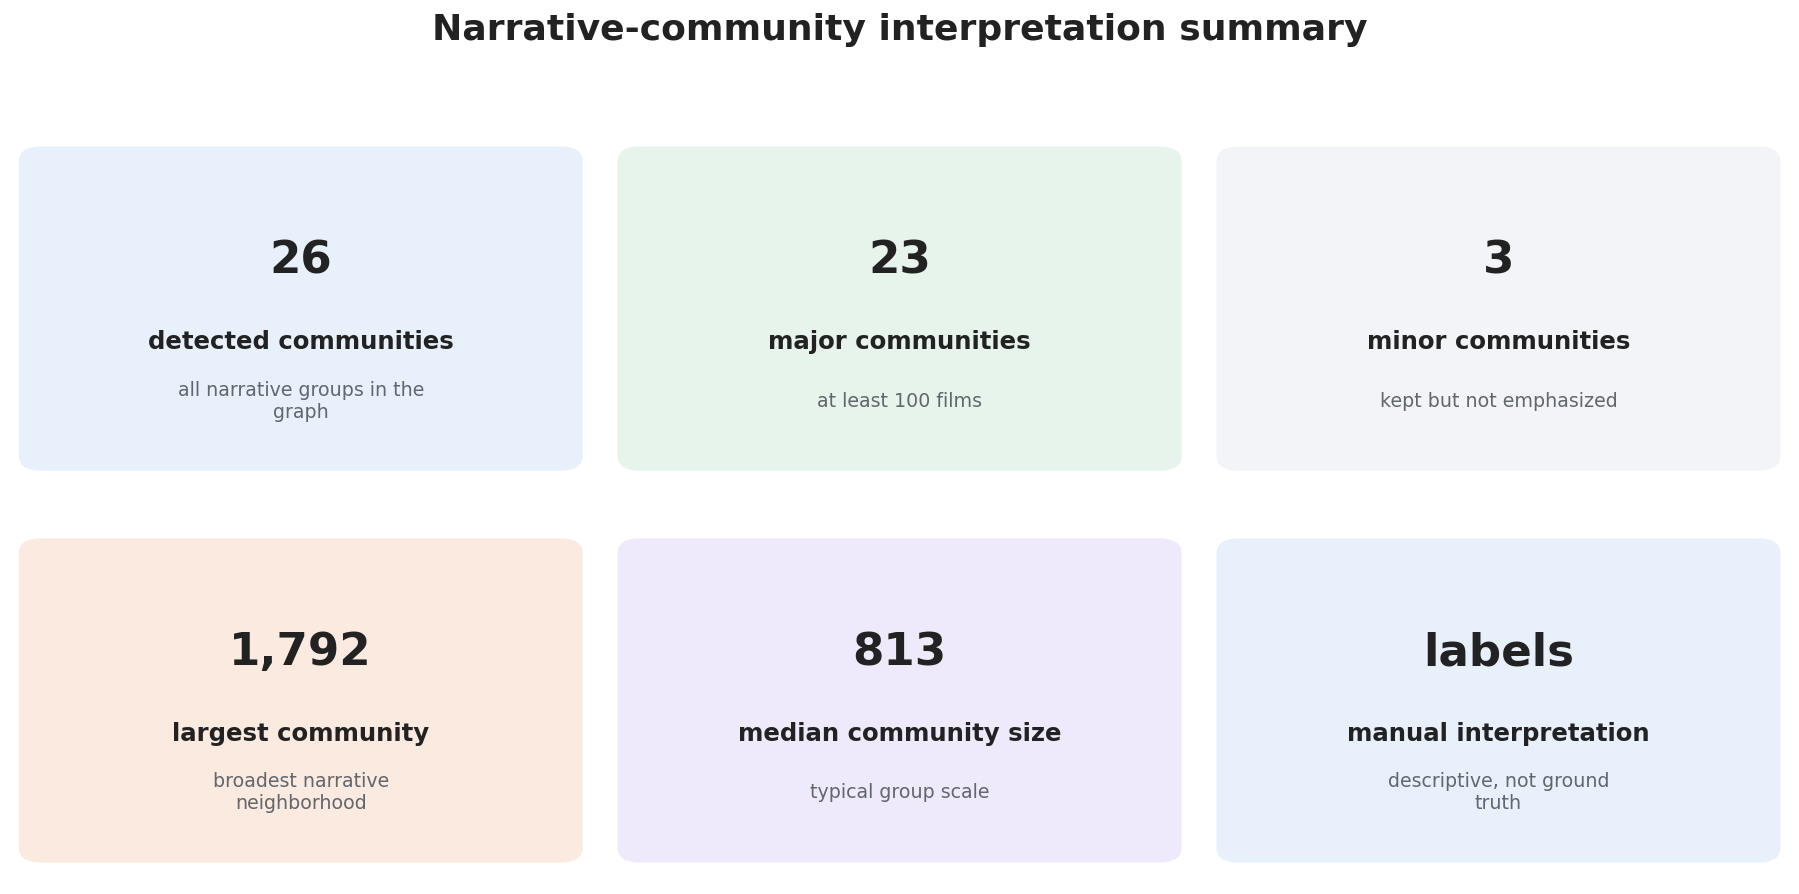

In [ ]:

cards = [
    ("26", "detected communities", "all narrative groups in the graph", COL["light_blue"]),
    (str(int(major_count)), "major communities", f"at least {major_threshold} films", COL["light_green"]),
    (str(int(minor_count)), "minor communities", "kept but not emphasized", COL["light_gray"]),
    (f"{profile['n_films'].max():,}", "largest community", "broadest narrative neighborhood", COL["light_orange"]),
    (f"{profile['n_films'].median():.0f}", "median community size", "typical group scale", COL["light_purple"]),
    ("labels", "manual interpretation", "descriptive, not ground truth", COL["light_blue"]),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for ax, (value, title, subtitle, bg) in zip(axes, cards):
    ax.axis("off")
    rect = FancyBboxPatch(
        (0.04, 0.08), 0.92, 0.82,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        facecolor=bg,
        edgecolor="none"
    )
    ax.add_patch(rect)
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=25, fontweight="bold")
    ax.text(0.5, 0.40, title, ha="center", va="center", fontsize=13.5, fontweight="bold")
    ax.text(0.5, 0.24, wrap_text(subtitle, 28), ha="center", va="center", fontsize=10.5, color=COL["muted"])

fig.suptitle("Narrative-community interpretation summary", fontsize=20, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_fig(fig, "09_community_interpretation_summary.png")
plt.show()


## 13. Export interpretation note

In [ ]:

note = f"""
Brick 4 — Narrative communities interpretation note

This section should appear after network construction.

Main message:
Community detection divides the plot-similarity network into narrative neighborhoods. These communities are not strict genres. They are groups of films whose plot descriptions place them near one another in the semantic network.

Key numbers:
- Total detected communities: {total_communities}
- Major interpreted communities: {int(major_count)}
- Minor communities: {int(minor_count)}
- Largest community size: {int(profile['n_films'].max()):,} films
- Major-community threshold used for main interpretation: {major_threshold} films

Recommended main thesis figures:
1. 01_community_detection_concept.png
2. 02_major_communities_lollipop.png
3. 04_top_communities_index_table.png
4. Selected 05_community_profile_sheet_CXX.png figures
5. 06_representative_films_gallery.png

Recommended appendix/supporting figures:
1. 03_major_minor_community_split.png
2. 07_community_size_vs_median_year.png
3. 08_community_genre_mix_small_multiples.png
4. 09_community_interpretation_summary.png

Important wording:
The labels are descriptive interpretations of plot-based clusters. They should not be described as objective genre labels or ground-truth categories.
""".strip()

write_text(note, "brick_04_interpretation_note.txt")
print(note)


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/text/brick_04_interpretation_note.txt
Brick 4 — Narrative communities interpretation note

This section should appear after network construction.

Main message:
Community detection divides the plot-similarity network into narrative neighborhoods. These communities are not strict genres. They are groups of films whose plot descriptions place them near one another in the semantic network.

Key numbers:
- Total detected communities: 26
- Major interpreted communities: 23
- Minor communities: 3
- Largest community size: 1,792 films
- Major-community threshold used for main interpretation: 100 films

Recommended main thesis figures:
1. 01_community_detection_concept.png
2. 02_major_communities_lollipop.png
3. 04_top_communities_index_table.png
4. Selected 05_community_profile_sheet_CXX.png figures
5. 06_representative_films_gallery.png

Recommended appendix/supporting figures:
1. 03_major_minor

## 14. Output check

In [ ]:

print("Figures:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("-", p.name)

print("\nTables:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print("-", p.name)

print("\nText:")
for p in sorted(TEXT_DIR.glob("*.txt")):
    print("-", p.name)


Figures:
- 01_community_detection_concept.png
- 02_major_communities_lollipop.png
- 03_major_minor_community_split.png
- 04_top_communities_index_table.png
- 05_community_profile_sheet_C02.png
- 05_community_profile_sheet_C04.png
- 05_community_profile_sheet_C08.png
- 05_community_profile_sheet_C12.png
- 05_community_profile_sheet_C14.png
- 05_community_profile_sheet_C22.png
- 05_community_profile_sheet_C23.png
- 05_community_profile_sheet_C24.png
- 06_representative_films_gallery.png
- 07_community_size_vs_median_year.png
- 08_community_genre_mix_small_multiples.png
- 09_community_interpretation_summary.png

Tables:
- 00_community_profile_table.csv
- 02_major_communities_lollipop_data.csv
- 03_major_minor_community_split_table.csv
- 04_top_communities_index_table.csv
- 07_community_size_vs_median_year_data.csv

Text:
- brick_04_interpretation_note.txt
